<a href="https://colab.research.google.com/github/atul650505/milky-way-rotation-curve/blob/main/MilkyWay_Rotation_curve_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
# STEP 0 — Setup



### 0.1 — Install the one library that is not already there



In [ ]:



%pip -q install "astropy>=6.0" "openpyxl>=3.1"


print("Install finished.")
print("If Colab asks you to restart the runtime, do it, then run again from this cell.")

Install finished.
If Colab asks you to restart the runtime, do it, then run again from this cell.


### 0.2 — Load the tools



- `numpy` — arrays and arithmetic on lots of numbers at once
- `pandas` — tables, like a spreadsheet you can compute with
- `matplotlib` — plots
- `astropy` — reads FITS files
- `requests` — downloads files over the internet



In [ ]:


import os, io, json, math, time, shutil, zipfile, hashlib, datetime


from pathlib import Path



import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS




plt.rcParams.update({
    : (10, 6), "figure.dpi": 110, "font.size": 11,
    : True, "grid.alpha": 0.25,
    : False, "axes.spines.right": False,
})




BLUE, RED, GOLD, GREY, GREEN = "#2F5496", "#C00000", "#BF8F00", "#595959", "#2E7D32"



print("numpy", np.__version__, "| pandas", pd.__version__)
print("Tools ready.")

numpy 2.1.3 | pandas 2.2.3
Tools ready.


### 0.3 — A tiny helper we will use all the way through

**What we are doing.** Defining `check(...)`, which tests that something is true and says so
out loud.

**Why this matters more than it looks.** Most people who cannot code are not stuck on syntax —
they are stuck because they cannot tell whether a step worked. After every important step we
will run a `check`. If you see `PASS`, move on. If you see `FAIL`, stop and read the message.
Do not carry on hoping it fixes itself.

In [ ]:


def check(condition, message):






    print(("  PASS  " if condition else "  FAIL  ") + message)

    return bool(condition)




check(2 + 2 == 4,  "arithmetic still works")
check(2 + 2 == 5,  "this one is meant to fail, so you know what failure looks like")

  PASS  arithmetic still works
  FAIL  this one is meant to fail, so you know what failure looks like


False

---
# STEP 1 — The dials

**This is the only part of the notebook you normally edit.**

Every choice the analysis makes lives here, in four small cells. That is deliberate: a choice
buried inside the code halfway down is a choice nobody can find, argue with, or report.



### 1.1 — Where in the sky we look

**The physics.** The tangent-point method only works when the line of sight passes *inside* the
Sun's orbit. That means Galactic longitude 0°–90° (Quadrant I) or 270°–360° (Quadrant IV).
Between 90° and 270° you are looking out of the Galaxy and there is no tangent point at all.

Inside Quadrant I we still trim both ends:

- **below ~15°** the tangent point falls inside about 2 kpc, where the Galactic bar throws the
  gas onto strongly non-circular orbits and the whole framework breaks;
- **above ~80°** the signal we are trying to measure has shrunk to a few km/s, smaller than the
  turbulent width of the line itself.

**Latitude.** The hydrogen disk is thin — a few hundred parsecs against a diameter of tens of
kiloparsecs, proportionally thinner than a sheet of paper. Averaging over |b| ≤ 0.5° keeps us
inside it and averages about twelve rows of pixels, which quietens the noise for free.

In [ ]:



LON_MIN     = 15.0
LON_MAX     = 80.0
LAT_ABS_MAX = 0.5





print(f"Looking at l = {LON_MIN}-{LON_MAX} deg,  averaging over |b| <= {LAT_ABS_MAX} deg")

Looking at l = 15.0-80.0 deg,  averaging over |b| <= 0.5 deg


### 1.2 — Which quadrant that puts us in, and which velocities to keep

**What we are doing.** Working out from the longitudes above whether we are in Quadrant I or
Quadrant IV, and then choosing the velocity range to load accordingly.

**Why this is not just bookkeeping.** In Quadrant I the tangent-point gas is moving *away* from
us, so its velocity is positive. In Quadrant IV it is moving *towards* us and the velocity is
negative. A velocity window that is right for one is wrong for the other.



In [ ]:



if 0.0 < LON_MIN and LON_MAX < 90.0:
    QUADRANT = "I"

    VELOCITY_MIN, VELOCITY_MAX = -150.0, +300.0
elif 270.0 < LON_MIN and LON_MAX < 360.0:
    QUADRANT = "IV"
    VELOCITY_MIN, VELOCITY_MAX = -300.0, +150.0
else:


    raise ValueError(
        f"l = {LON_MIN}-{LON_MAX} deg spans no single quadrant with a tangent point.\n"
        )


SEARCH_MIN = 15.0
SEARCH_MAX = 260.0



  print(f"Quadrant {QUADRANT}: loading velocities {VELOCITY_MIN:+.0f} to {VELOCITY_MAX:+.0f} km/s")
  print(f"Hunting for the edge between {SEARCH_MIN} and {SEARCH_MAX} km/s from zero")

  check(SEARCH_MAX <= max(abs(VELOCITY_MIN), abs(VELOCITY_MAX)),
        )

Quadrant I: loading velocities -150 to +300 km/s
Hunting for the edge between 15.0 and 260.0 km/s from zero
  PASS  the search window fits inside the velocities we are loading


True

### 1.3 — How we decide the emission has ended


A spectrum does not stop at a cliff. Turbulence inside the gas clouds smears the cut-off over
8–10 km/s, so we have to *declare* where it ends, using a rule applied identically everywhere.

Two rules are on offer:

- `"absolute"` — the line ends where brightness drops below a fixed number of kelvin. **We're using this.**
- `"fraction"` — the line ends at some percentage of that sightline's own peak. Sounds cleverer,
  is actually unstable: the peak moves around from sightline to sightline, so the rule quietly
  means something different at every longitude. Below about l = 16° it fails outright.

`MIN_CHANNELS = 3` stops a single noisy channel, or one faint cloud drifting past, being
mistaken for the edge of the Galaxy.

In [ ]:



THRESHOLD_METHOD = "absolute"
ABSOLUTE_K       = 10.0
PEAK_FRACTION    = 0.20
MIN_CHANNELS     = 3




print("Edge rule: " + (f"brightness falls below {ABSOLUTE_K} K"
                       if THRESHOLD_METHOD == "absolute"
                       else f"brightness falls below {PEAK_FRACTION:.0%} of the local peak"))
print(f"          and it must have stayed above for at least {MIN_CHANNELS} channels")

check(THRESHOLD_METHOD in ("absolute", "fraction"), "the edge rule is one we recognise")

Edge rule: brightness falls below 10.0 K
          and it must have stayed above for at least 3 channels
  PASS  the edge rule is one we recognise


True

### 1.4 — Grouping, and the self-calibration

**Grouping.** The telescope beam is 16.2 arcminutes across and the data grid is 5 arcminutes,
so about three neighbouring columns are looking through the same blur at the same patch of sky.
They are not three independent measurements. We group them into 0.25° bins — roughly one bin
per beam — so the final curve does not look better sampled than it really is.



In [ ]:
LON_BIN_DEG = 0.25


CALIBRATE_EDGE_BIAS = True
CALIB_LON_MIN       = 70.0


OUTPUT_DIR = Path("mw_rotation_results")


for sub in ["raw", "processed", "figures"]:


    (OUTPUT_DIR / sub).mkdir(parents=True, exist_ok=True)

print(f"Grouping sightlines into {LON_BIN_DEG} deg bins")
print(f"Self-calibration: {'ON' if CALIBRATE_EDGE_BIAS else 'OFF'}"
      + (f", using l >= {CALIB_LON_MIN} deg" if CALIBRATE_EDGE_BIAS else ""))
print(f"Results will be written to: {OUTPUT_DIR.resolve()}")
check(CALIB_LON_MIN < LON_MAX, "the calibration region is inside the range we observe")

Grouping sightlines into 0.25 deg bins
Self-calibration: ON, using l >= 70.0 deg
Results will be written to: /content/mw_rotation_results
  PASS  the calibration region is inside the range we observe


True

---
# STEP 2 — Constants



$R_0$ is how far the Sun sits from the Galactic Centre. $\Theta_0$ is how fast the Sun's
neighbourhood orbits. Both come from other people's work — mainly VLBI parallaxes of masers in
star-forming regions, which give trigonometric distances with no rotation assumptions at all.

They set the **radius scale** and the **velocity zero-point** of every single point on our final
curve. Change them and the whole curve moves. So:



In [ ]:

NU_0_MHZ    = 1420.405752
LAMBDA_0_CM = 21.106
C_KMS       = 2.99792458e5






R0_KPC      = 8.15
THETA0_KMS  = 236.0

R0_ERR_KPC     = 0.15
THETA0_ERR_KMS = 7.0



G_ASTRO     = 4.30091e-6

print(f"R0     = {R0_KPC} +/- {R0_ERR_KPC} kpc")
print(f"Theta0 = {THETA0_KMS} +/- {THETA0_ERR_KMS} km/s")

print(f"Omega0 = {THETA0_KMS/R0_KPC:.2f} km/s/kpc   (how fast we go round, per kpc)")

R0     = 8.15 +/- 0.15 kpc
Theta0 = 236.0 +/- 7.0 km/s
Omega0 = 28.96 km/s/kpc   (how fast we go round, per kpc)


### 2.1 — Check the units

**What we are doing.** Feeding a textbook example through our mass formula to see whether it
gives the textbook answer.

**Why.** `G` has been converted into unusual units — kpc, km/s and solar masses — so that
$M = \Theta^2 R / G$ comes out directly in solar masses with no conversion factors anywhere.
That conversion is exactly the kind of thing that is silently wrong. So we test it.

**What we should see.** About 9.0 × 10¹⁰ solar masses, and a PASS.

In [ ]:


M_test = 220.0**2 * 8.0 / G_ASTRO


print(f"M(<8 kpc) for a 220 km/s curve = {M_test:.3e} Msun")


check(8.5e10 < M_test < 9.5e10, "the mass formula and its units are correct")

M(<8 kpc) for a 220 km/s curve = 9.003e+10 Msun
  PASS  the mass formula and its units are correct


True

---
# STEP 3 — HI4PI

**What we are doing.** The HI4PI survey is not one giant file. The sky is cut into 18 cubes
along the Galactic equator, named `CAR_E01` to `CAR_E18`, each centred 20° from its neighbour
and each about 22° wide — so neighbours overlap slightly. We work out which ones cover the
longitudes we asked for in Step 1.

Each cube is roughly 264 MB.

In [ ]:
CDS_BASE = "https://cdsarc.cds.unistra.fr/ftp/J/A+A/594/A116/CUBES/GAL/CAR"
CUBE_HALF_WIDTH_DEG = 11.1




cubes = pd.DataFrame({




    :        [f"CAR_E{n:02d}" for n in range(1, 19)],
    : [10.0 + 20.0 * (n - 1) for n in range(1, 19)],
})



cubes["lon_lo"] = cubes["glon_centre"] - CUBE_HALF_WIDTH_DEG
cubes["lon_hi"] = cubes["glon_centre"] + CUBE_HALF_WIDTH_DEG
cubes["url"]    = CDS_BASE + "/" + cubes["name"] + ".fits"


print(f"The survey is split into {len(cubes)} cubes along the Galactic equator.")


cubes[["name", "glon_centre", "lon_lo", "lon_hi"]].head()

The survey is split into 18 cubes along the Galactic equator.


,name,glon_centre,lon_lo,lon_hi
0,CAR_E01,10.0,-1.1,21.1
1,CAR_E02,30.0,18.9,41.1
2,CAR_E03,50.0,38.9,61.1
3,CAR_E04,70.0,58.9,81.1
4,CAR_E05,90.0,78.9,101.1


### 3.1 — Picking the ones that overlap our longitudes

**How the selection works.** A cube is useful if its range overlaps ours at all. Two ranges
overlap when *each one starts before the other ends*:

```
cube ends after we start     AND     cube starts before we end
   lon_hi >= LON_MIN                    lon_lo <= LON_MAX
```

That single line is the whole test.

In [ ]:



overlaps = (cubes["lon_hi"] >= LON_MIN) & (cubes["lon_lo"] <= LON_MAX)


needed   = cubes[overlaps].reset_index(drop=True)

print(f"We asked for l = {LON_MIN}-{LON_MAX} deg")

print(f"That needs {len(needed)} cubes, roughly {len(needed)*264} MB to download\n")
print(needed[["name", "glon_centre", "lon_lo", "lon_hi"]].to_string(index=False))
check(len(needed) >= 1, "at least one cube covers the longitudes we asked for")

We asked for l = 15.0-80.0 deg
That needs 5 cubes, roughly 1320 MB to download

   name  glon_centre  lon_lo  lon_hi
CAR_E01         10.0    -1.1    21.1
CAR_E02         30.0    18.9    41.1
CAR_E03         50.0    38.9    61.1
CAR_E04         70.0    58.9    81.1
CAR_E05         90.0    78.9   101.1
  PASS  at least one cube covers the longitudes we asked for


True

---
# STEP 4 — Download the data



In [ ]:

def download_file(url, destination, chunk_mb=8):

    destination = Path(destination)



    if destination.exists() and destination.stat().st_size > 1_000_000:

        print(f"  already have {destination.name} "
              f"({destination.stat().st_size/1e6:.0f} MB), skipping")
    else:
        t0 = time.time()



        with requests.get(url, stream=True, timeout=180) as response:
            response.raise_for_status()
            total, done = int(response.headers.get("content-length", 0)), 0
            with open(destination, "wb") as fh:

                for block in response.iter_content(chunk_size=chunk_mb * 1024 * 1024):
                    fh.write(block)
                    done += len(block)
                    pct = 100 * done / total if total else 0


                    print(f"\r  {destination.name}: {done/1e6:6.0f} MB "
                          f"({pct:5.1f}%)  [{time.time()-t0:4.0f} s]", end="")
        print()




    digest = hashlib.sha256()
    with open(destination, "rb") as fh:

        for block in iter(lambda: fh.read(1 << 20), b""):
            digest.update(block)

    return destination, digest.hexdigest()

print("Downloader ready.")

Downloader ready.


### 4.1 — Run the downloads



In [ ]:
downloads = []



for _, row in needed.iterrows():
    print(f"{row['name']}:")


    path, sha = download_file(row["url"], OUTPUT_DIR / "raw" / f"{row['name']}.fits")


    downloads.append({"name": row["name"], "path": str(path), "sha256": sha,
                      : round(path.stat().st_size / 1e6, 1)})


downloads = pd.DataFrame(downloads)
print("\nOn disk:")
print(downloads[["name", "size_mb"]].to_string(index=False))

print(f"\nFirst fingerprint: {downloads.loc[0,'sha256'][:32]}...")


check((downloads["size_mb"] > 100).all(), "every file is a plausible size (not an error page)")

CAR_E01:
  already have CAR_E01.fits (264 MB), skipping
CAR_E02:
  already have CAR_E02.fits (264 MB), skipping
CAR_E03:
  already have CAR_E03.fits (264 MB), skipping
CAR_E04:
  already have CAR_E04.fits (264 MB), skipping
CAR_E05:
  already have CAR_E05.fits (264 MB), skipping

On disk:
   name  size_mb
CAR_E01    264.1
CAR_E02    264.1
CAR_E03    264.1
CAR_E04    264.1
CAR_E05    264.1

First fingerprint: 04b70693289f3300d997c4d3ea1fd06f...
  PASS  every file is a plausible size (not an error page)


True

---
# STEP 5 — Look inside a data cube



### What a "cube" actually is

A radio telescope pointed at 21 cm does not record one number per direction. It records a whole
*spectrum*, because gas moving at different speeds shows up at slightly different frequencies.
Do that for every direction on a patch of sky and you get a three-dimensional block of numbers:

$$T_B(v,\ b,\ l)$$

brightness temperature, as a function of velocity, Galactic latitude and Galactic longitude.
The clearest mental picture is a **stack of sky images, one image per velocity channel**. HI4PI
cubes are 266 × 266 pixels on the sky with 933 velocity channels.

### How a FITS file says which pixel is where

Each axis carries three keywords, and the rule that turns a pixel number into a coordinate:

$$\text{coord}(k) = \big[(k+1) - \texttt{CRPIX}\big]\times\texttt{CDELT} + \texttt{CRVAL}$$

- `CRVAL` — the coordinate at the reference pixel
- `CRPIX` — which pixel that is (FITS counts from 1, Python counts from 0 — hence the `+1`)
- `CDELT` — how much the coordinate changes per pixel

### 5.1 — Read the velocity axis

**What we are doing.** Turning channel numbers into velocities in km/s.

**The trap this cell exists to avoid.** HI4PI stores velocity in **metres** per second, not
kilometres. The unit keyword usually says so — but header keywords are written by humans and are
wrong more often than you would like. So we check the keyword *and* we sanity-check the size of
the numbers: if the biggest velocity is over 10,000, it cannot be km/s for Galactic hydrogen,
so it must be m/s.

Belt and braces. That is not paranoia, it is how you avoid a factor of 1000 that would be
invisible in a table and obvious in a plot.

In [ ]:
def velocity_axis(hdr):



    n = hdr["NAXIS3"]




    v = (np.arange(n) + 1 - hdr["CRPIX3"]) * hdr["CDELT3"] + hdr["CRVAL3"]




    unit = str(hdr.get("CUNIT3", "")).strip().lower().replace(" ", "")



    looks_like_metres = unit in ("m/s", "ms-1", "m.s-1") or np.abs(v).max() > 1e4
    if looks_like_metres:
        v = v / 1000.0
    return v



print("velocity_axis defined.")

velocity_axis defined.


### 5.2 — Read the two sky axes

**What we are doing.** Getting longitude and latitude in degrees for every pixel.

**Why we hand this to astropy.** Turning pixels into sky coordinates involves map projections —
the same problem as flattening a globe onto paper. Astropy's `WCS` machinery knows about them
and we should not reinvent that. We ask it for one row of longitudes and one column of
latitudes, which is all we need since the two are independent in this projection.

The `np.mod(..., 360)` at the end wraps longitude into 0–360°, so that −5° becomes 355°.

In [ ]:
def sky_axes(hdr):





    w = WCS(hdr).celestial
    nx, ny = hdr["NAXIS1"], hdr["NAXIS2"]






    lon, _ = w.wcs_pix2world(np.arange(nx), np.full(nx, ny // 2), 0)
    _, lat = w.wcs_pix2world(np.full(ny, nx // 2), np.arange(ny), 0)

    return np.mod(np.asarray(lon, float), 360.0), np.asarray(lat, float)

print("sky_axes defined.")

sky_axes defined.


### 5.3 — Actually opening one and looking

**What you should see.** A shape of roughly (933, 266, 266), a velocity step of about 1.29 km/s,
and a note that we will keep only about a third of the channels. The rest sit at velocities where
there is no disk gas at all, so loading them would be a waste.

In [ ]:
def describe_cube(path):



    with fits.open(path, memmap=True) as hdul:
        hdr = hdul[0].header
        print(f"--- {Path(path).name} ---")
        print(f"Shape (velocity, latitude, longitude) = "
              f"({hdr['NAXIS3']}, {hdr['NAXIS2']}, {hdr['NAXIS1']})")



        for i in (1, 2, 3):
            print(f"  axis {i}: {hdr.get(f'CTYPE{i}','?'):12s} "
                  f"CRVAL={hdr.get(f'CRVAL{i}'):>12} CRPIX={hdr.get(f'CRPIX{i}'):>7} "
                  f"CDELT={hdr.get(f'CDELT{i}'):>12} unit={hdr.get(f'CUNIT{i}','?')}")
        print(f"  brightness unit: {hdr.get('BUNIT','?')}")


        velocity, (lon, lat) = velocity_axis(hdr), sky_axes(hdr)




    print(f"\n  velocity : {velocity.min():8.1f} to {velocity.max():8.1f} km/s, "
          f"step {np.median(np.diff(velocity)):.3f}")
    print(f"  longitude: {lon.min():8.3f} to {lon.max():8.3f} deg")
    print(f"  latitude : {lat.min():8.3f} to {lat.max():8.3f} deg")


    n_keep = int(((velocity >= VELOCITY_MIN) & (velocity <= VELOCITY_MAX)).sum())
    print(f"\n  we will load {n_keep} of {velocity.size} channels "
          f"({100*n_keep/velocity.size:.0f}%). The rest hold no disk gas.")
    return velocity, lon, lat


v_demo, lon_demo, lat_demo = describe_cube(downloads.loc[0, "path"])



check(0.5 < abs(np.median(np.diff(v_demo))) < 3.0,
      )
check(abs(lat_demo).min() < LAT_ABS_MAX,
      )

--- CAR_E01.fits ---
Shape (velocity, latitude, longitude) = (933, 266, 266)
  axis 1: GLON-CAR     CRVAL=        10.0 CRPIX=  134.0 CDELT=-0.0833333333 unit=deg
  axis 2: GLAT-CAR     CRVAL=         0.0 CRPIX=133.0000000528 CDELT=0.0833333333 unit=deg
  axis 3: VRAD         CRVAL=         0.0 CRPIX=466.921630003202 CDELT=1288.21496912415 unit=m/s
  brightness unit: K

  velocity :   -600.2 to    600.4 km/s, step 1.288
  longitude:    0.000 to  359.917 deg
  latitude :  -11.000 to   11.083 deg

  we will load 349 of 933 channels (37%). The rest hold no disk gas.
  PASS  velocity channels are about 1.3 km/s wide, so the axis is in km/s not m/s
  PASS  the cube contains pixels inside our latitude strip


True

---
# STEP 6 — Squash the cube into one picture

**What we are doing.** Turning the three-dimensional cube into a two-dimensional map by
averaging over latitude:

$$T_B(v,b,l) \ \xrightarrow[\ |b|\le 0.5^\circ\ ]{\text{average}}\ T_B(v,l)$$

**Why we are allowed to.** The hydrogen disk is thin and the geometry of the tangent point
assumes the gas sits in the midplane. At a typical tangent-point distance of 7 kpc, half a
degree is a height of only about 60 pc — comfortably inside the layer. So averaging across it
throws away nothing we wanted, and averaging about twelve independent rows of pixels beats the
noise down for free.

**What comes out** is the **longitude–velocity diagram**, and it is the most useful single image
in the whole practical.

### 6.1 — Read one cube and squash it

**Reading the code.** The three `keep_` lines build *masks* — lists of True/False, one per pixel,
saying "do we want this one". Then we read only the slab we need rather than the whole 264 MB.

`np.nanmean(..., axis=1)` averages along axis 1, which is latitude. `nan` in the name means
"ignore any missing values rather than letting one poison the average".

>
>
> The function makes **three masks** — one for velocity, one for latitude, one for longitude —
> each a list of True/False the same length as that axis. Nothing has been read from disk yet;
> we are only deciding *what* to read.
>
> Then three guards. The first is not an error at all: some cubes simply sit elsewhere on the
> sky, so it returns `None` and the caller skips them. The other two are real errors and stop
> the run, naming the setting to change.
>
> Then `np.flatnonzero` finds where each mask is True, and we take the first and last so we can
> grab one continuous block — far faster than picking channels one at a time off a 264 MB file.
>
> Then the one line that matters: `np.nanmean(..., axis=1)` averages away the latitude axis,
> turning a 3-D block into a 2-D picture.


In [ ]:
def extract_lv(path, lon_min, lon_max, lat_abs_max, v_min, v_max):

    with fits.open(path, memmap=True) as hdul:
        hdu, hdr = hdul[0], hdul[0].header
        velocity, (lon, lat) = velocity_axis(hdr), sky_axes(hdr)




        keep_v   = (velocity >= v_min) & (velocity <= v_max)
        keep_lat = np.abs(lat) <= lat_abs_max
        keep_lon = (lon >= lon_min) & (lon <= lon_max)





        if keep_lon.sum() < 3:
            return None
        if keep_lat.sum() < 1:
            raise RuntimeError("No latitude pixels selected. Increase LAT_ABS_MAX.")
        if keep_v.sum() < 20:
            raise RuntimeError("Too few velocity channels. Widen VELOCITY_MIN/MAX.")





        z = np.flatnonzero(keep_v);   z0, z1 = z.min(), z.max() + 1
        y = np.flatnonzero(keep_lat); y0, y1 = y.min(), y.max() + 1



        slab = np.asarray(hdu.data[z0:z1, y0:y1, :], dtype=np.float32)





        lv = np.nanmean(slab[:, :, keep_lon], axis=1)
        return velocity[z0:z1], lon[keep_lon], lv

print("extract_lv defined.")

extract_lv defined.


### 6.2 — Doing it for every cube and glue the results together

**What we are doing.** Running the previous function on each cube and joining the pieces into
one wide map.

**Two things this cell has to be careful about, both fixed here:**

1. **Different cubes could have slightly different velocity grids.** If so we interpolate them
   onto the first cube's grid. The original version tested this with `np.allclose(a, b)`, which
   *crashes* rather than returning False when the two arrays have different lengths — exactly the
   case it was written to catch. We check the shape first.

2. **Neighbouring cubes overlap by about 2°**, so some longitudes appear twice. We keep one copy
   of each, using a tolerance rather than exact equality, because two cubes can put a column at
   30.0000 and 30.0001 degrees and those are the same sightline.

In [ ]:


velocity_master, lon_pieces, lv_pieces = None, [], []

for _, row in downloads.iterrows():
    result = extract_lv(row["path"], LON_MIN, LON_MAX, LAT_ABS_MAX,
                        VELOCITY_MIN, VELOCITY_MAX)
    if result is None:
        print(f"{row['name']}: no overlap with our longitudes, skipped")
        continue
    v_i, lon_i, lv_i = result

    if velocity_master is None:
        velocity_master = v_i




    elif v_i.shape != velocity_master.shape or not np.allclose(v_i, velocity_master):
        print(f"  ({row['name']} had a different velocity grid, interpolating)")



        lv_i = np.vstack([np.interp(velocity_master, v_i, lv_i[:, j])
                          for j in range(lv_i.shape[1])]).T

    lon_pieces.append(lon_i); lv_pieces.append(lv_i)
    print(f"{row['name']}: {lv_i.shape[1]:4d} sightlines x {lv_i.shape[0]} channels")



longitude = np.concatenate(lon_pieces)
lv        = np.hstack(lv_pieces)
velocity  = velocity_master





order = np.argsort(longitude)
longitude, lv = longitude[order], lv[:, order]





keep = np.r_[True, np.diff(longitude) > 1e-4]
n_dupes = int((~keep).sum())
longitude, lv = longitude[keep], lv[:, keep]

print(f"\nRemoved {n_dupes} duplicated sightlines from the cube overlaps")

print(f"Final l-v diagram: {lv.shape[0]} channels x {lv.shape[1]} sightlines")
print(f"  longitude {longitude.min():.2f} to {longitude.max():.2f} deg")
print(f"  brightest pixel {np.nanmax(lv):.1f} K")



check(np.all(np.diff(longitude) > 0), "sightlines are in increasing longitude order, no repeats")
check(50 < np.nanmax(lv) < 500, "the brightest pixel is a believable H I brightness")

CAR_E01:   73 sightlines x 349 channels
CAR_E02:  266 sightlines x 349 channels
CAR_E03:  266 sightlines x 349 channels
CAR_E04:  253 sightlines x 349 channels
CAR_E05:   12 sightlines x 349 channels

Removed 90 duplicated sightlines from the cube overlaps
Final l-v diagram: 349 channels x 780 sightlines
  longitude 15.08 to 80.00 deg
  brightest pixel 129.1 K
  PASS  sightlines are in increasing longitude order, no repeats
  PASS  the brightest pixel is a believable H I brightness


True

### 6.3 — Looking at it



- **across** — where we pointed the telescope
- **up** — the Doppler velocity of the gas
- **colour** — how much hydrogen is emitting at that velocity, in that direction

The bright body is the hydrogen disk. The streaky diagonal filaments running through it are
**spiral arms**, seen edge-on from inside. You are looking at the structure of the Galaxy.

**The feature that matters is the upper boundary.** Trace it with a finger: it starts high on the
left and slides steadily down to the right. That boundary is the rotation curve in disguise, and
every remaining step is about tracing it and re-plotting it in physical units.

Notice too the emission at *negative* velocity along the bottom. That is gas in the **outer**
Galaxy, beyond the Sun's orbit. It is real, it is right there in our data, and the tangent-point
method cannot use a single photon of it. Step 14 explains why.

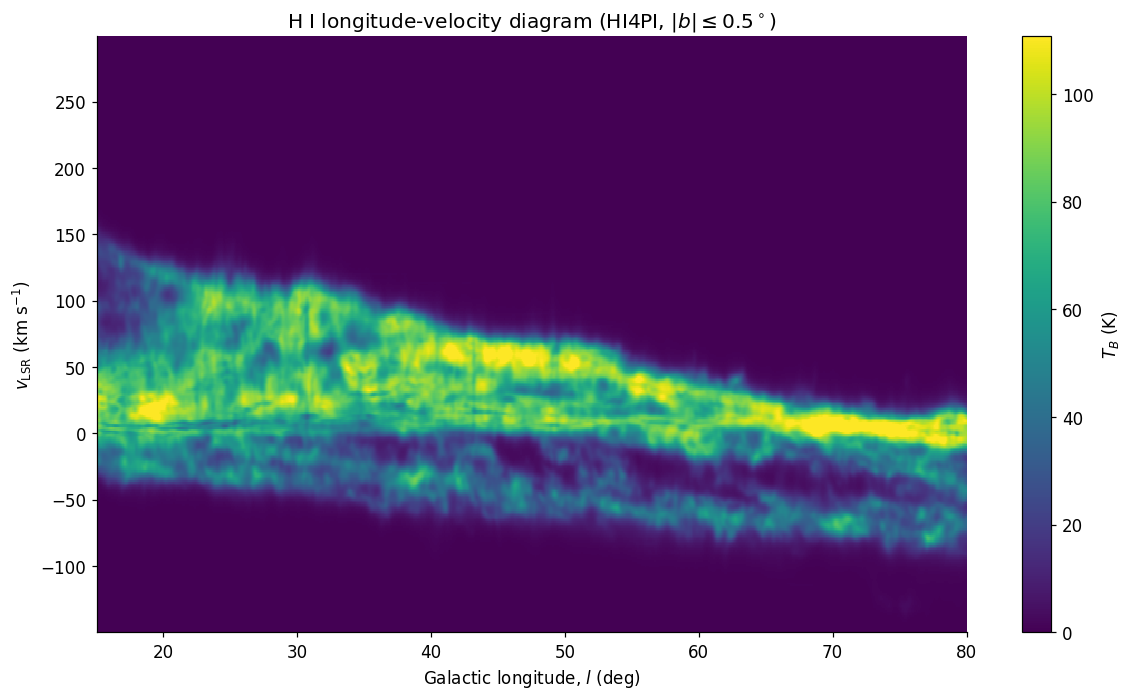

This image holds 780 sightlines, one per vertical column.


In [ ]:


fig, ax = plt.subplots(figsize=(11, 6.5))



im = ax.pcolormesh(longitude, velocity, lv, shading="auto", cmap="viridis",
                   vmin=0, vmax=np.nanpercentile(lv, 99.5))


ax.set_xlabel("Galactic longitude, $l$ (deg)")
ax.set_ylabel(r"$v_{\rm LSR}$ (km s$^{-1}$)")
ax.set_title(rf"H I longitude-velocity diagram (HI4PI, $|b| \leq {LAT_ABS_MAX}^\circ$)")
ax.grid(False)
fig.colorbar(im, ax=ax, label="$T_B$ (K)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figures" / "01_lv_diagram.png", dpi=150)
plt.show()

print(f"This image holds {lv.shape[1]} sightlines, one per vertical column.")

---
# STEP 7 — Looking at real spectra before measuring anything

**What we are doing.** Taking six vertical slices out of that picture and plotting them
individually. A single column of the l–v diagram *is* a spectrum: brightness against velocity
for one direction.

### Three things to look for

**Several peaks.** Each is a different cloud complex somewhere along that line of sight. Point
down the Galactic plane and the beam passes through hydrogen at every distance, all of it arriving
added together. From the spectrum alone you cannot tell how far away any of it is.

**A sharp drop on the high-velocity side.** That drop is the tangent point. Beyond it there is
simply no gas on that sightline moving that fast.

**The drop is not vertical.** Turbulence inside the clouds smears it over 8–10 km/s. Deciding
where along that slope the gas "ends" is the central judgement of the entire experiment.



> *The peaks are the loudest part of the signal. Why not just use the tallest peak?*

Because **the height of a peak tells you how much gas there is, not how fast it is moving.**
Position along the axis is speed; height is quantity. They are independent. The tallest peak is
usually a fat spiral arm, or the local gas near v = 0, and where it sits is an accident of where
clouds happen to be. The right-hand edge is not an accident — it is fixed by geometry.

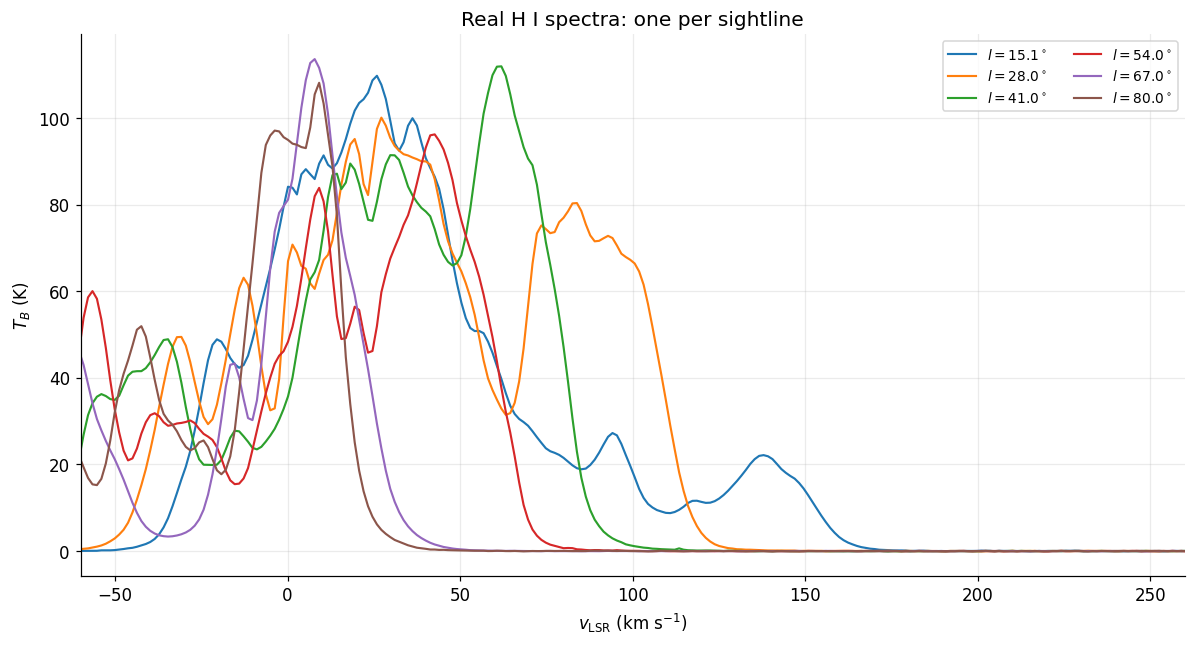

Watch the right-hand edges. They march steadily leftward as l increases.
That is not an artefact. That IS the measurement.
As l grows, the tangent point moves out towards the Sun's own orbit, where the gas
travels at nearly our own speed, so little of its motion shows up as a Doppler shift.
At l = 90 deg the tangent point would be the Sun itself, and v_term would be zero.


In [ ]:



sample_idx = np.linspace(0, longitude.size - 1, 6).astype(int)

fig, ax = plt.subplots(figsize=(11, 6))
for j in sample_idx:


    ax.plot(velocity, lv[:, j], lw=1.4, label=rf"$l = {longitude[j]:.1f}^\circ$")
ax.set_xlabel(r"$v_{\rm LSR}$ (km s$^{-1}$)")
ax.set_ylabel("$T_B$ (K)")
ax.set_title("Real H I spectra: one per sightline")
ax.set_xlim(-60, SEARCH_MAX)
ax.legend(fontsize=9, ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figures" / "02_sample_spectra.png", dpi=150)
plt.show()

print("Watch the right-hand edges. They march steadily leftward as l increases.")
print("That is not an artefact. That IS the measurement.")
print("As l grows, the tangent point moves out towards the Sun's own orbit, where the gas")
print("travels at nearly our own speed, so little of its motion shows up as a Doppler shift.")
print("At l = 90 deg the tangent point would be the Sun itself, and v_term would be zero.")

---
# STEP 8 — Measuring the edge

**This is the measurement. Everything before it was preparation; everything after it is
arithmetic.** So we take it in seven small pieces.

### The physics, said carefully

Along a sightline in Quadrant I, every parcel of gas contributes some part of its circular motion
to our line of sight. Most of it is moving partly sideways relative to us, and sideways motion
produces no Doppler shift at all. Only the component along the sightline counts:

$$v_{\text{measured}} = v_{\text{circular}}\cos\theta$$

At the **tangent point** — the point on the sightline closest to the Galactic Centre — that angle
is exactly zero. All of the motion is along our line of sight. Nothing else on that sightline can
appear faster. That maximum is the **terminal velocity**, $v_{\text{term}}$.

>  The tangent-point gas is **not moving
> faster** than the other gas. Every cloud on that sightline orbits at roughly the same speed.
> The tangent point is simply the one place where none of that speed is hidden sideways.

### The problem

If the edge were a clean vertical cliff we would read it off and go home. It is not. Turbulence
and beam smearing spread it over 10 to 20 km/s. So we must adopt a **criterion** and apply it
identically at every longitude.

| Criterion | How it works | Where it goes wrong |
|:--|:--|:--|
| Fraction of peak | threshold = 20% of this sightline's peak | the threshold moves between sightlines, so the rule means something different at each longitude — and below l ≈ 16° it fails outright |
| **Fixed brightness** | threshold = 10 K, everywhere | depends on an adopted number, which must therefore be reported |
| Half-power of the edge | threshold = T_edge / 2 | unbiased in principle, but needs T_edge measured per sightline |

We use the fixed threshold, and Step 10 deals with the bias it leaves behind.

### 8.1 — Helper: find runs of consecutive channels

**What we are doing.** Given a list of True/False, find where the unbroken stretches of True
start and end.

**Why we need it.** The rule "emission must stay above the threshold for at least 3 channels in a
row" is what stops one noisy channel, or a faint cloud drifting past, being mistaken for the edge
of the Galaxy. To apply it we need to know how long each stretch is.

**How it works.** Pad with False at both ends, then look at where the value *changes*. A change
from False to True (+1) starts a run; True to False (−1) ends one.

The cell tests itself on a short example so we can see the answer is right by eye.

In [ ]:
def contiguous_runs(mask):

    a = np.asarray(mask, bool)


    padded = np.r_[False, a, False]


    change = np.diff(padded.astype(int))


    return list(zip(np.flatnonzero(change == 1).tolist(),
                    (np.flatnonzero(change == -1) - 1).tolist()))



demo = [False, True, True, True, False, False, True, False]

print("input :", demo)
print("runs  :", contiguous_runs(demo), "  <- one run over 1-3, another at 6-6")
check(contiguous_runs(demo) == [(1, 3), (6, 6)], "runs are found correctly")

input : [False, True, True, True, False, False, True, False]
runs  : [(1, 3), (6, 6)]   <- one run over 1-3, another at 6-6
  PASS  runs are found correctly


True

### 8.2 —  Which quadrant is this sightline in?

**What we are doing.** Returning +1 in Quadrant I, −1 in Quadrant IV, and 0 where there is no
tangent point at all.

**Why.** In Quadrant I the tangent-point gas recedes, so we hunt for the most *positive*
velocity. In Quadrant IV it approaches, so we hunt for the most *negative*. Rather than write the
measurement twice, we multiply the velocity axis by this sign, do the work once for the
"most positive" case, and multiply back at the end.

In [ ]:
def quadrant_sign(lon_deg):

    l = np.mod(lon_deg, 360.0)


    if 0.0   < l < 90.0:  return +1.0
    if 270.0 < l < 360.0: return -1.0
    return 0.0





for test_l in [30, 300, 180]:
    print(f"  l = {test_l:3d} deg -> sign {quadrant_sign(test_l):+.0f}")
check(quadrant_sign(30) == 1 and quadrant_sign(300) == -1 and quadrant_sign(180) == 0,
      )

  l =  30 deg -> sign +1
  l = 300 deg -> sign -1
  l = 180 deg -> sign +0
  PASS  the three quadrant cases are handled


True

### 8.3 — The measurement itself



1. **Flip if needed.** Multiply by the quadrant sign so we are always looking for the most
   positive velocity.
2. **Restrict to the search window.** Ignore everything below 15 km/s, which is the bright local
   gas near zero, and everything above 260 km/s, which is faster than anything inside the Sun's
   orbit.
3. **Set the threshold.** A fixed number of kelvin, or a fraction of the peak.
4. **Find the runs above it**, and throw away any shorter than 3 channels.
5. **Take the run that reaches furthest out.** That is the edge.
6. **Interpolate between channels.** The true crossing lies somewhere *between* the last channel
   above the threshold and the first one below it, so we work out where by drawing a straight line
   between the two. This buys sub-channel precision for free.

**It never crashes.** If something goes wrong it returns a `flag` explaining what, and the value
`nan` — "not a number". That matters when we are running it 840 times: one bad sightline should
not kill the whole run, but it must not be silently mistaken for a good one either.

>
>
> Two Python things worth knowing before you start:
>
> `lambda r: u[r[1]]` is a **throwaway one-line function**. It appears in
> `max(runs, key=lambda r: u[r[1]])`, which does not want the biggest run — it wants the run
> whose *end* sits at the highest velocity. The `key` says what to judge each run on.
>
> `dict(...)` builds a **dictionary**: a set of labelled values. Every exit from this function
> returns one, so the caller always gets the same shape of answer whether the measurement
> succeeded or failed. The `flag` label says which.


In [ ]:






def measure_terminal_velocity(velocity, spectrum, lon_deg,
                              search_min=SEARCH_MIN, search_max=SEARCH_MAX,
                              method=THRESHOLD_METHOD, fraction=PEAK_FRACTION,
                              absolute_k=ABSOLUTE_K, min_channels=MIN_CHANNELS):





    sign = quadrant_sign(lon_deg)
    if sign == 0.0:
        return dict(terminal_velocity_kms=np.nan, threshold_k=np.nan,
                    peak_tb_k=np.nan, flag="NO_TANGENT_POINT")





    u, T = sign * np.asarray(velocity, float), np.asarray(spectrum, float)
    order = np.argsort(u)
    u, T = u[order], T[order]




    window = (u >= search_min) & (u <= search_max) & np.isfinite(T)
    if window.sum() < 5:
        return dict(terminal_velocity_kms=np.nan, threshold_k=np.nan,
                    peak_tb_k=np.nan, flag="EMPTY_WINDOW")




    peak = float(np.nanmax(T[window]))
    threshold = fraction * peak if method == "fraction" else float(absolute_k)






    above = window & (T >= threshold)
    runs = [r for r in contiguous_runs(above) if (r[1] - r[0] + 1) >= min_channels]
    if not runs:
        return dict(terminal_velocity_kms=np.nan, threshold_k=threshold,
                    peak_tb_k=peak, flag="NO_DETECTION")






    i_start, i_end = max(runs, key=lambda r: u[r[1]])
    u_edge = u[i_end]







    if i_end + 1 < u.size and np.isfinite(T[i_end + 1]) and T[i_end] > T[i_end + 1]:
        f = (T[i_end] - threshold) / (T[i_end] - T[i_end + 1])
        u_edge = u[i_end] + f * (u[i_end + 1] - u[i_end])



    channel = abs(float(np.median(np.diff(u))))
    flag = "CHECK_EDGE" if u_edge >= search_max - 2 * channel else "OK"


    return dict(terminal_velocity_kms=float(sign * u_edge),
                threshold_k=float(threshold), peak_tb_k=peak, flag=flag)

print("measure_terminal_velocity defined.")

measure_terminal_velocity defined.


### 8.4 — Watch it work on a single spectrum

**What we are doing.** Running the function on one sightline and printing every intermediate
number, then drawing the result.

**Why this cell exists.** A function you cannot see inside is a function you have to take on
trust. Here you can check each of the six moves by eye before we let it loose on 840 sightlines.


Sightline at l = 36.75 deg

  1. quadrant sign        : +1
  2. channels in window   : 190
  3. peak in window       : 94.6 K
     threshold used       : 10.0 K
  6. terminal velocity    : 99.4 km/s
     quality flag         : OK

  ...which will become  R = 4.88 kpc  and  Theta = 241 km/s


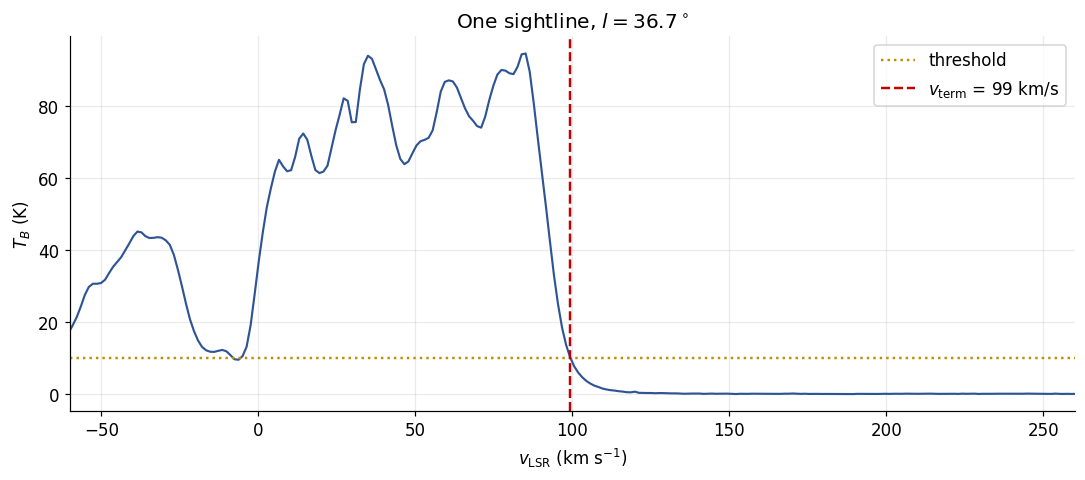

In [ ]:




TEST_INDEX = len(longitude) // 3


l_test, spec = longitude[TEST_INDEX], lv[:, TEST_INDEX]
res = measure_terminal_velocity(velocity, spec, l_test)


print(f"Sightline at l = {l_test:.2f} deg\n")
print(f"  1. quadrant sign        : {quadrant_sign(l_test):+.0f}")
print(f"  2. channels in window   : {int(((velocity>=SEARCH_MIN)&(velocity<=SEARCH_MAX)).sum())}")
print(f"  3. peak in window       : {res['peak_tb_k']:.1f} K")
print(f"     threshold used       : {res['threshold_k']:.1f} K")
print(f"  6. terminal velocity    : {res['terminal_velocity_kms']:.1f} km/s")
print(f"     quality flag         : {res['flag']}")


sin_l = abs(np.sin(np.deg2rad(l_test)))
print(f"\n  ...which will become  R = {R0_KPC*sin_l:.2f} kpc  and  "
      f"Theta = {abs(res['terminal_velocity_kms']) + THETA0_KMS*sin_l:.0f} km/s")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(velocity, spec, color=BLUE, lw=1.4)


ax.axhline(res["threshold_k"], color=GOLD, ls=":", lw=1.6, label="threshold")
ax.axvline(res["terminal_velocity_kms"], color=RED, ls="--", lw=1.6,

           label=rf"$v_{ \rm term} $ = {res['terminal_velocity_kms']:.0f} km/s")
ax.set_xlim(-60, SEARCH_MAX); ax.set_xlabel(r"$v_{\rm LSR}$ (km s$^{-1}$)")
ax.set_ylabel("$T_B$ (K)"); ax.set_title(rf"One sightline, $l = {l_test:.1f}^\circ$")
ax.legend(); fig.tight_layout(); plt.show()

### 8.5 — Run it on every sightline

**What we are doing.** The same function, once per column of the l–v diagram. About 840 of them.

**What you should see.** Almost all flags `OK`. A handful of `CHECK_EDGE` is normal — those are
sightlines where the edge landed suspiciously close to the end of the search window. We keep
track of them and we will **exclude them from the
result** rather than plotting them separately and quietly using them anyway.

In [ ]:
records = []


for j, lon_j in enumerate(longitude):
    r = measure_terminal_velocity(velocity, lv[:, j], lon_j)
    r["longitude_deg"] = float(lon_j)
    records.append(r)



terminal = pd.DataFrame(records)[
    ["longitude_deg", "terminal_velocity_kms", "threshold_k", "peak_tb_k", "flag"]]

print(f"Measured {len(terminal)} sightlines.")

print("Flags:", terminal["flag"].value_counts().to_dict())

print(f"\nv_term runs from {terminal.terminal_velocity_kms.min():.1f} "
      f"to {terminal.terminal_velocity_kms.max():.1f} km/s")
print(f"Threshold {terminal.threshold_k.median():.1f} K against "
      f"a typical peak of {terminal.peak_tb_k.median():.1f} K")



frac_ok = (terminal["flag"] == "OK").mean()
check(frac_ok > 0.9, f"at least 90% of sightlines gave a clean edge (got {frac_ok:.0%})")
terminal.head(8)

Measured 780 sightlines.
Flags: {'OK': 780}

v_term runs from 19.5 to 153.2 km/s
Threshold 10.0 K against a typical peak of 96.9 K
  PASS  at least 90% of sightlines gave a clean edge (got 100%)


,longitude_deg,terminal_velocity_kms,threshold_k,peak_tb_k,flag
0,15.083333,153.189452,10.0,109.710686,OK
1,15.166667,152.632286,10.0,108.208015,OK
2,15.250000,151.687662,10.0,106.959114,OK
3,15.333333,150.681124,10.0,105.324394,OK
4,15.416667,150.023297,10.0,104.229561,OK
5,15.500000,149.626778,10.0,103.313232,OK
6,15.583333,149.228822,10.0,101.946373,OK
7,15.666667,148.893167,10.0,99.625214,OK


### 8.6 — Where did the rule actually put the line?

**What we are doing.** Drawing six spectra with the threshold and the resulting edge marked.

**What to look for.** The gold line should sit at the same height in every panel, because we
chose a fixed threshold. Switch `THRESHOLD_METHOD` back to `"fraction"` in Step 1.3 and re-run:
the gold line then jumps around from panel to panel, and at the highest longitude it drops to a
completely different scale. **That instability is the reason we abandoned it.**

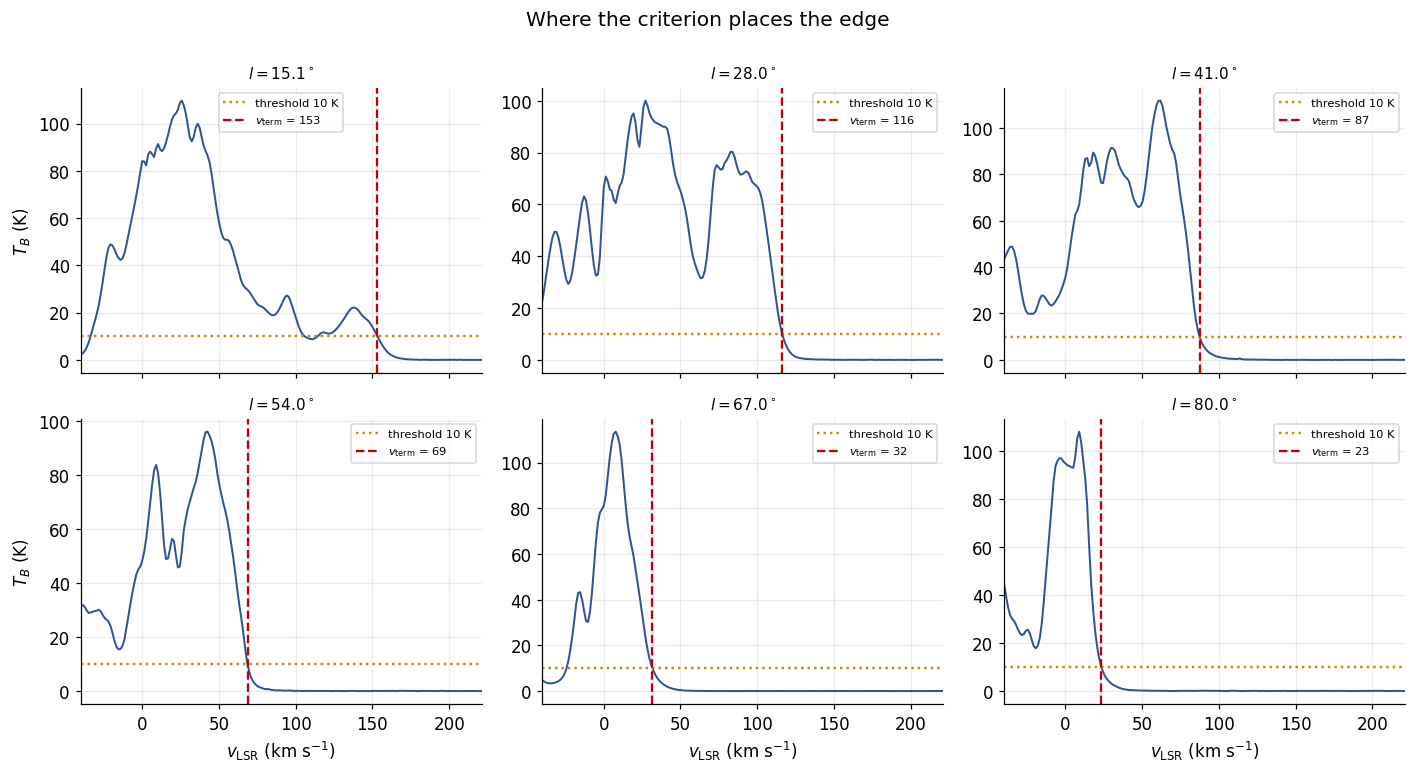

In [ ]:


fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)


for ax, j in zip(axes.ravel(), sample_idx):
    row = terminal.iloc[j]
    ax.plot(velocity, lv[:, j], color=BLUE, lw=1.3)
    ax.axhline(row.threshold_k, color=GOLD, ls=":", lw=1.6,
               label=f"threshold {row.threshold_k:.0f} K")
    ax.axvline(row.terminal_velocity_kms, color=RED, ls="--", lw=1.5,
               label=rf"$v_{ \rm term} $ = {row.terminal_velocity_kms:.0f}")
    ax.set_title(rf"$l = {row.longitude_deg:.1f}^\circ$", fontsize=10)
    ax.set_xlim(-40, SEARCH_MAX * 0.85)
    ax.legend(fontsize=7.5)






for ax in axes[-1]:   ax.set_xlabel(r"$v_{\rm LSR}$ (km s$^{-1}$)")
for ax in axes[:, 0]: ax.set_ylabel("$T_B$ (K)")
fig.suptitle("Where the criterion places the edge", y=1.00)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figures" / "04_threshold_on_spectra.png", dpi=150)
plt.show()

### 8.7 — THE QUALITY GATE



We overlay the measured terminal velocities on the l–v diagram. The test is simple:

- the white points must **hug** the upper edge of the emission;
- floating in the dark empty space above the gas means the threshold is too low and you are
  chasing noise;
- cutting into the bright body means it is too high and you are truncating real signal.

**Why it earns its place.** This one picture catches sign errors, frame errors, off-by-one channel
errors and threshold failures, all in a single glance.

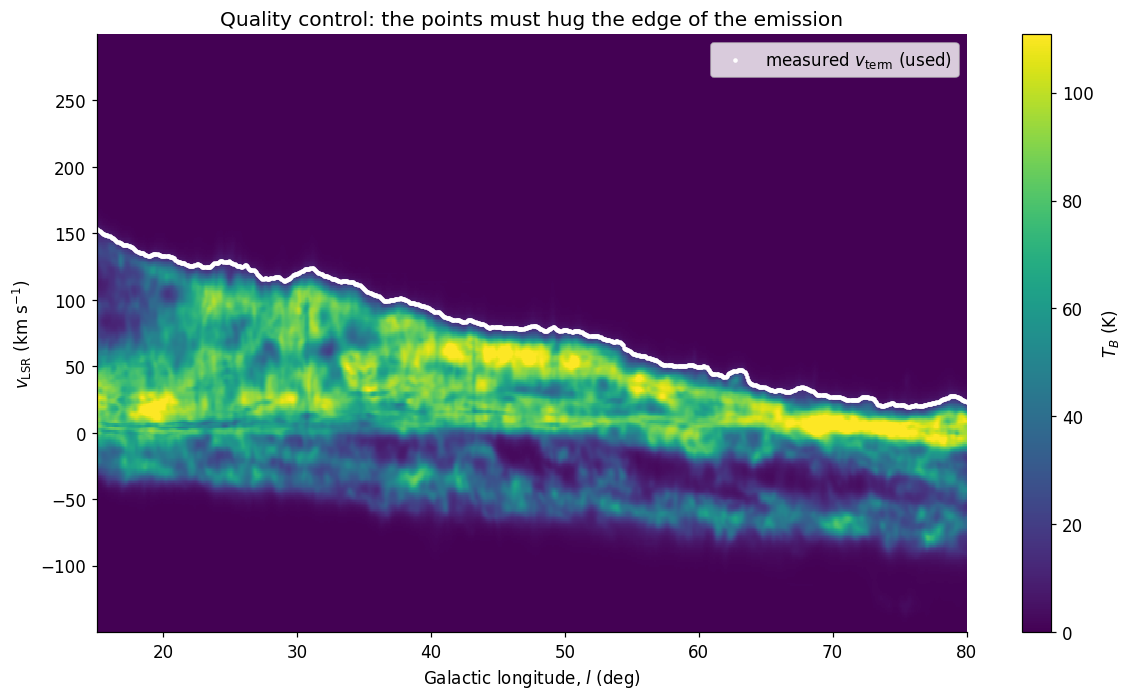

780 of 780 sightlines gave a clean edge (100%).
If the white trace breaks into isolated dots anywhere, stop and find out why.


In [ ]:

fig, ax = plt.subplots(figsize=(11, 6.5))
im = ax.pcolormesh(longitude, velocity, lv, shading="auto", cmap="viridis",
                   vmin=0, vmax=np.nanpercentile(lv, 99.5))

ok  = terminal["flag"] == "OK"
bad = terminal["flag"] == "CHECK_EDGE"


ax.plot(terminal.loc[ok, "longitude_deg"], terminal.loc[ok, "terminal_velocity_kms"],
        , ms=4, color="white", label=r"measured $v_{\rm term}$ (used)")


if bad.any():
    ax.plot(terminal.loc[bad, "longitude_deg"], terminal.loc[bad, "terminal_velocity_kms"],
            , ms=6, color=RED, label="flagged, will be dropped")
ax.set_xlabel("Galactic longitude, $l$ (deg)")
ax.set_ylabel(r"$v_{\rm LSR}$ (km s$^{-1}$)")
ax.set_title("Quality control: the points must hug the edge of the emission")
ax.legend(loc="upper right"); ax.grid(False)
fig.colorbar(im, ax=ax, label="$T_B$ (K)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figures" / "03_terminal_velocity_overlay.png", dpi=150)
plt.show()





print(f"{int(ok.sum())} of {len(terminal)} sightlines gave a clean edge ({ok.mean():.0%}).")
print("If the white trace breaks into isolated dots anywhere, stop and find out why.")

---
# STEP 9 — Group neighbouring sightlines

**What we are doing.** Combining sightlines into 0.25° bins and taking the median of each group.

**Why.** Neighbouring columns are not independent measurements. The beam is 16.2 arcmin across
and the grid is 5 arcmin, so about three columns are looking through the same blur at the same
patch of sky. Real turbulence correlates over similar scales too. Plotting all 840 as separate
points would claim far more information than we have.

**Why the median and not the mean.** The median ignores the occasional sightline where a stray
cloud fools the threshold. A mean would let that one sightline drag the whole group.

**About the error bars** With only about three sightlines per bin, a
standard deviation is a very noisy estimate. So we impose a floor of 8 km/s, which is roughly what
H I turbulence contributes no matter what. In practice the floor wins nearly everywhere. These
bars are therefore best described as *"the irreducible turbulent width"*, **not** as a statistical
uncertainty.

 Equal steps in longitude are not equal steps in
radius, because $R = R_0\sin l$. A 0.25° bin covers about 31 pc of radius at l = 30° but only 6 pc
at l = 80°. That is why the points crowd together near the Sun's orbit in the final plot. It is
geometry, not extra data.

In [ ]:
def bin_by_longitude(table, bin_width_deg, only_ok=True):



    good = table[np.isfinite(table["terminal_velocity_kms"])]
    if only_ok and "flag" in good.columns:
        good = good[good["flag"] == "OK"]


    good = good.copy()





    origin = np.floor(good["longitude_deg"].min() / bin_width_deg) * bin_width_deg
    good["bin"] = np.floor((good["longitude_deg"] - origin) / bin_width_deg).astype(int)



    binned = good.groupby("bin", as_index=False).agg(
        longitude_deg=("longitude_deg", "median"),


        terminal_velocity_kms=("terminal_velocity_kms", "median"),
        scatter_kms=("terminal_velocity_kms", "std"),
        n_sightlines=("longitude_deg", "size"),
    )





    binned["scatter_kms"] = binned["scatter_kms"].fillna(0.0).clip(lower=8.0)
    return binned.drop(columns="bin")


binned = bin_by_longitude(terminal, LON_BIN_DEG)
n_used = int((terminal["flag"] == "OK").sum())
print(f"{len(terminal)} sightlines -> {n_used} usable -> {len(binned)} bins of {LON_BIN_DEG} deg")
print(f"Median sightlines per bin: {binned.n_sightlines.median():.0f}")




dR = R0_KPC * np.cos(np.deg2rad([30, 50, 80])) * np.deg2rad(LON_BIN_DEG) * 1000
print(f"\nOne bin covers {dR[0]:.0f} pc of radius at l = 30 deg, "
      f"{dR[1]:.0f} pc at 50 deg, {dR[2]:.0f} pc at 80 deg.")
check(binned.n_sightlines.median() >= 2, "each bin combines at least a couple of sightlines")
binned.head()

780 sightlines -> 780 usable -> 260 bins of 0.25 deg
Median sightlines per bin: 3

One bin covers 31 pc of radius at l = 30 deg, 23 pc at 50 deg, 6 pc at 80 deg.
  PASS  each bin combines at least a couple of sightlines


,longitude_deg,terminal_velocity_kms,scatter_kms,n_sightlines
0,15.166667,152.632286,8.0,3
1,15.416667,150.023297,8.0,3
2,15.666667,148.893167,8.0,3
3,15.916667,148.201153,8.0,3
4,16.166667,146.709831,8.0,3


---
# STEP 10 — The systematic the data finds by itself





As $l \to 90^\circ$ the tangent point moves out to $R \to R_0$: the Sun's own orbit. At that
radius the circular speed is $\Theta_0$ **by definition**, because $\Theta_0$ is what we adopted
for the Local Standard of Rest. So near $l = 90^\circ$ our measurement has **no freedom at all**.
It must converge on $\Theta_0$.

Rearranging $\Theta(R) = v_{\rm term} + \Theta_0\sin l$, the terminal velocity we *ought* to
measure at high longitude is

$$v_{\rm term}^{\rm ideal} = \Theta_0\,(1 - \sin l)$$

At l = 80° that is only 3.6 km/s. Now compare it with what we actually measured.

### What we find, and why

The measured edge sits systematically **beyond** the ideal. The reason is physical, not a bug:
turbulence inside the clouds (about 9 km/s) and beam smearing push the wing of the line outward,
so the emission appears to extend to slightly higher velocity than the bulk gas is really moving.

This is an **additive** offset in $v_{\rm term}$, so it propagates straight into $\Theta$ at every
radius. At l = 20° it is a small percentage of a 130 km/s signal and invisible. At l = 80° the
true signal is only 3.6 km/s and the bias is the entire measurement.

### Why subtracting it is not circular reasoning

We use $\Theta_0$ **only where the geometry forces $\Theta = \Theta_0$ anyway**. We assume nothing
about the answer at any other radius. And because the correction is additive, it moves the
*zero point* of the curve and leaves the *shape* untouched — which we check in Step 11.



This one number is really at least three things added together: the edge bias, the beam smearing,
and the ~3 km/s mismatch between the radio and dynamical definitions of the Local Standard of Rest
that this notebook never applies. Calling it `EDGE_BIAS` is convenient shorthand, not a claim that
it is purely an edge effect.

In [ ]:
def measure_edge_bias(binned_table, calib_lon_min, theta0=THETA0_KMS, verbose=True):



    calib = binned_table[binned_table["longitude_deg"] >= calib_lon_min].copy()
    if len(calib) < 3:


        if verbose:
            print(f"Only {len(calib)} bins above l = {calib_lon_min} deg. Cannot calibrate.")
        return 0.0, calib




    calib["sin_l"]        = np.abs(np.sin(np.deg2rad(calib["longitude_deg"])))



    calib["v_term_ideal"] = theta0 * (1.0 - calib["sin_l"])
    calib["v_term_meas"]  = calib["terminal_velocity_kms"].abs()
    calib["excess"]       = calib["v_term_meas"] - calib["v_term_ideal"]


    bias = float(np.median(calib["excess"]))
    if verbose:

        print(f"Calibrating on {len(calib)} bins with l >= {calib_lon_min} deg\n")
        show = calib[["longitude_deg", "v_term_meas", "v_term_ideal", "excess"]].round(1)
        show.columns = ["l (deg)", "measured", "ideal", "excess"]
        print(show.to_string(index=False, max_rows=12))
        print(f"\nMedian excess: {bias:.1f} km/s")
        print("This is what we subtract from every terminal velocity.")
        print("It is an empirical correction for THIS extraction, not a universal constant.")



    return bias, calib


if CALIBRATE_EDGE_BIAS:
    EDGE_BIAS, calib = measure_edge_bias(binned, CALIB_LON_MIN)
else:
    EDGE_BIAS, calib = 0.0, None
    print("Self-calibration is switched OFF.")

Calibrating on 40 bins with l >= 70.0 deg

 l (deg)  measured  ideal  excess
    70.1      26.7   14.1    12.6
    70.4      27.0   13.7    13.3
    70.7      26.2   13.3    12.9
    70.9      25.2   13.0    12.2
    71.2      24.5   12.6    11.9
    71.4      24.9   12.3    12.6
     ...       ...    ...     ...
    78.7      27.0    4.6    22.4
    78.9      28.0    4.4    23.6
    79.2      27.4    4.2    23.2
    79.4      26.5    4.0    22.4
    79.7      24.9    3.8    21.0
    79.9      23.8    3.6    20.2

Median excess: 13.6 km/s
This is what we subtract from every terminal velocity.
It is an empirical correction for THIS extraction, not a universal constant.


### 10.1 — See the two curves that ought to meet

**What we should see.** A red line collapsing towards zero at l = 90°, and blue points that do
not collapse with it. The gap between them at high longitude is our own systematic, laid bare.

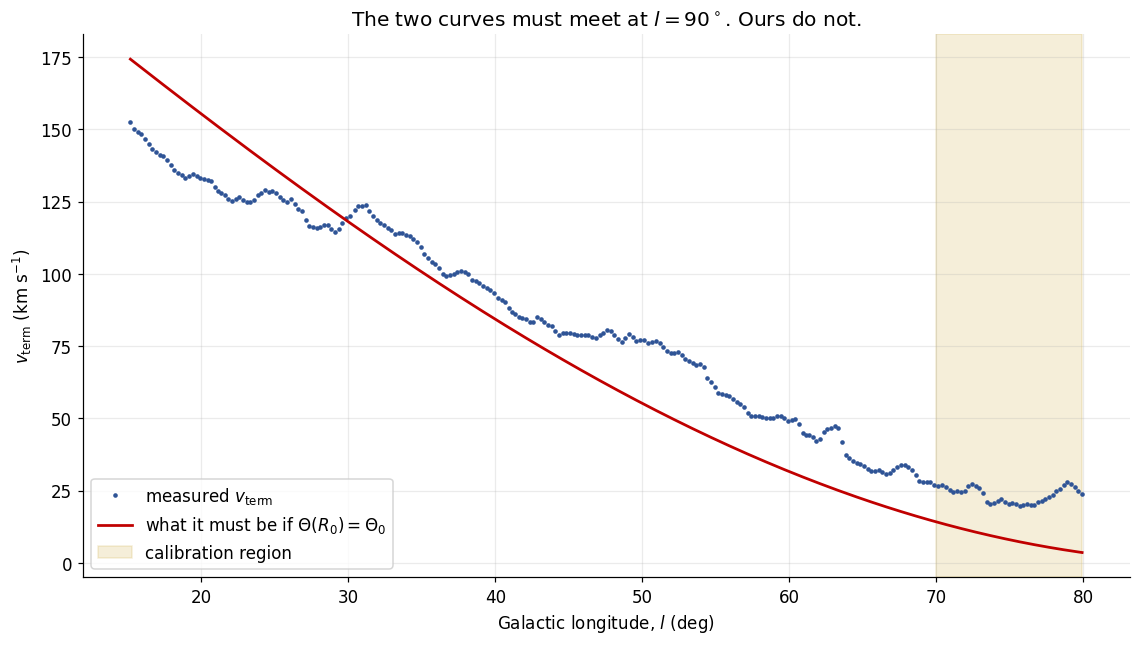

Correction to apply: 13.6 km/s subtracted from every v_term.


In [ ]:


b2 = binned.copy()
b2["sin_l"]        = np.abs(np.sin(np.deg2rad(b2["longitude_deg"])))
b2["v_term_ideal"] = THETA0_KMS * (1.0 - b2["sin_l"])
b2["v_term_meas"]  = b2["terminal_velocity_kms"].abs()

fig, ax = plt.subplots(figsize=(10.5, 6))

ax.plot(b2["longitude_deg"], b2["v_term_meas"], ".", ms=4, color=BLUE,
        label=r"measured $v_{\rm term}$")
ax.plot(b2["longitude_deg"], b2["v_term_ideal"], "-", color=RED, lw=1.8,
        label=r"what it must be if $\Theta(R_0)=\Theta_0$")

ax.axvspan(CALIB_LON_MIN, b2["longitude_deg"].max(), color=GOLD, alpha=0.15,
           label="calibration region")
ax.set_xlabel("Galactic longitude, $l$ (deg)")
ax.set_ylabel(r"$v_{\rm term}$ (km s$^{-1}$)")
ax.set_title(r"The two curves must meet at $l = 90^\circ$. Ours do not.")
ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figures" / "10_edge_bias_calibration.png", dpi=150)
plt.show()



print(f"Correction to apply: {EDGE_BIAS:.1f} km/s subtracted from every v_term.")

### 10.2 — How much does the criterion matter? (a fair comparison)

**What we are doing.** Re-measuring everything with seven different edge rules and comparing.


Here each criterion is calibrated with **its own** high-longitude bias before we compare. The
right-hand column is the honest one.

**Two things to notice in the output.**

The **20%-of-peak criterion breaks at low longitude.** Below about l = 16° the spectrum dips below
the threshold partway out, the algorithm treats that dip as the end of the line, and real emission
running out to 200 km/s is thrown away.

And **the corrected column is far tighter than the uncorrected one.** That is the whole argument
for doing the calibration: the criterion matters enormously to the raw number, and much less once
each one is held to the constraint at l = 90°.

In [ ]:



trials = [
    ("fraction of peak, 50%", dict(method="fraction", fraction=0.50)),
    ("fraction of peak, 20%", dict(method="fraction", fraction=0.20)),
    ("fraction of peak, 10%", dict(method="fraction", fraction=0.10)),
    ("absolute, 20 K",        dict(method="absolute", absolute_k=20.0)),
    ("absolute, 10 K",        dict(method="absolute", absolute_k=10.0)),
    ("absolute,  5 K",        dict(method="absolute", absolute_k=5.0)),
    ("absolute,  2 K",        dict(method="absolute", absolute_k=2.0)),
]

rows = []


for label, kwargs in trials:
    recs = []
    for j, lon_j in enumerate(longitude):



        r = measure_terminal_velocity(velocity, lv[:, j], lon_j, **kwargs)
        r["longitude_deg"] = float(lon_j)
        recs.append(r)
    tbl = pd.DataFrame(recs)
    bnd = bin_by_longitude(tbl, LON_BIN_DEG)






    bias, _ = measure_edge_bias(bnd, CALIB_LON_MIN, verbose=False)
    sin_l   = np.abs(np.sin(np.deg2rad(bnd["longitude_deg"])))
    raw     = bnd["terminal_velocity_kms"].abs() + THETA0_KMS * sin_l
    cor     = (bnd["terminal_velocity_kms"].abs() - bias) + THETA0_KMS * sin_l

    rows.append({"criterion": label,
                 : round(bias, 1),
                 : round(float(np.median(raw)), 1),
                 : round(float(np.median(cor)), 1)})

comparison = pd.DataFrame(rows)
print("Each criterion, calibrated against its OWN high-longitude bias:\n")
print(comparison.to_string(index=False))





spread_raw = comparison["median Theta, raw"].max() - comparison["median Theta, raw"].min()
spread_cor = comparison["median Theta, corrected"].max() - comparison["median Theta, corrected"].min()
print(f"\nSpread across criteria: {spread_raw:.0f} km/s raw, {spread_cor:.0f} km/s corrected.")
print(f"The telescope noise is 0.043 K. None of that spread came from the instrument.")
print("It came from a decision an analyst made. That is worth learning early.")

Each criterion, calibrated against its OWN high-longitude bias:

            criterion  own bias (km/s)  median Theta, raw  median Theta, corrected
fraction of peak, 50%             11.3              240.6                    229.2
fraction of peak, 20%             15.9              245.1                    229.2
fraction of peak, 10%             18.9              247.8                    228.9
       absolute, 20 K             12.1              244.3                    232.2
       absolute, 10 K             13.6              247.5                    233.8
       absolute,  5 K             17.1              250.7                    233.6
       absolute,  2 K             22.4              255.3                    232.9

Spread across criteria: 15 km/s raw, 5 km/s corrected.
The telescope noise is 0.043 K. None of that spread came from the instrument.
It came from a decision an analyst made. That is worth learning early.


---
# STEP 11 — The rotation curve


### Where are we looking?

At the tangent point the radius vector from the Galactic Centre is perpendicular to our line of
sight, so the right-angled triangle Sun–Centre–tangent point gives

$$\boxed{R = R_0\,|\sin l|}$$

Notice what is *not* in that equation: **any distance measurement whatsoever.** Pure geometry.
That is why this experiment works with a modest telescope and a laptop — and also why it can
never reach beyond $R_0$, since $|\sin l| \le 1$.

### How fast is it going?

The velocity we measure is the *difference* between the tangent-point gas's motion along our
sightline and the Sun's own motion along the same direction. Adding our own motion back on:

$$\boxed{\Theta(R) = |v_{\rm term}| + \Theta_0\,|\sin l|}$$

Every sightline yields exactly one point $(R, \Theta)$.

 At l = 24° with
$v_{\rm term} = 123$ km/s:

$$R = 8.15\sin 24^\circ = 3.31 \text{ kpc}, \qquad \Theta = 123 + 236\sin 24^\circ = 123 + 96 = 219 \text{ km/s}$$

### 11.1 — The conversion, and a sign trap worth understanding

**The bug this cell fixes.** The obvious way to write this function is

```python
Theta = np.abs(v_term) + Theta0 * sin_l      # WRONG once a correction is applied
```

The `abs` is there to handle Quadrant IV, where terminal velocities are negative. But we have
just *subtracted* a bias of order 15 km/s, and at the highest longitudes the measured $v_{\rm term}$
is itself only 10–20 km/s. So the corrected value can legitimately go **negative** — and `abs`
would flip it back to positive, pushing $\Theta$ **up** instead of down.

That is bad in a particularly sneaky way: it happens exactly in the region we use as our anchor,
and it makes the curve appear to converge on $\Theta_0$ beautifully when part of that convergence
is an artefact of the code.

**The fix.** Take the absolute value *once*, on the raw measurement, before the correction. After
that the number is signed and stays signed. If it goes negative, that is information — it means
the correction over-shot on that sightline — and we count how often it happens.

In [ ]:
def tangent_point_solution(lon_deg, v_term_signed, R0=R0_KPC, Theta0=THETA0_KMS):















    sin_l = np.abs(np.sin(np.deg2rad(np.asarray(lon_deg, float))))
    R     = R0 * sin_l
    Theta = np.asarray(v_term_signed, float) + Theta0 * sin_l
    return R, Theta


R_chk, Th_chk = tangent_point_solution(24.0, 123.0)
print(f"l = 24 deg, v_term = 123 km/s  ->  R = {R_chk:.2f} kpc, Theta = {Th_chk:.0f} km/s")
check(abs(R_chk - 3.31) < 0.02 and abs(Th_chk - 219) < 1,
      )

l = 24 deg, v_term = 123 km/s  ->  R = 3.31 kpc, Theta = 219 km/s
  PASS  the conversion reproduces the worked example


True

In [ ]:
curve = binned.copy()
curve["sin_l"]     = np.abs(np.sin(np.deg2rad(curve["longitude_deg"])))
curve["v_term_abs"] = curve["terminal_velocity_kms"].abs()




_, curve["Theta_raw_kms"] = tangent_point_solution(
    curve["longitude_deg"], curve["v_term_abs"])





curve["v_term_corrected"] = curve["v_term_abs"] - EDGE_BIAS

curve["R_kpc"], curve["Theta_kms"] = tangent_point_solution(
    curve["longitude_deg"], curve["v_term_corrected"])



n_negative = int((curve["v_term_corrected"] < 0).sum())
curve["Theta_err_kms"] = curve["scatter_kms"]

curve = curve.sort_values("R_kpc").reset_index(drop=True)

print(f"Rotation curve: {len(curve)} points")
print(f"  radius        : {curve.R_kpc.min():.2f} to {curve.R_kpc.max():.2f} kpc")
print(f"  circular speed: {curve.Theta_kms.min():.0f} to {curve.Theta_kms.max():.0f} km/s")
print(f"  median        : {curve.Theta_kms.median():.0f} km/s")
if n_negative:
    print(f"\n  note: {n_negative} bins had the correction over-shoot into negative v_term.")
    print(f"        They are kept with their sign, which pulls Theta slightly below Theta0.")



print(f"\nCheck where the answer is fixed by definition:")
print(f"  Theta at R = {curve.R_kpc.iloc[-1]:.2f} kpc is {curve.Theta_kms.iloc[-1]:.0f} km/s")
print(f"  it should be close to Theta0 = {THETA0_KMS:.0f} km/s")

check(abs(curve.Theta_kms.iloc[-1] - THETA0_KMS) < 25,
      )

Rotation curve: 260 points
  radius        : 2.13 to 8.02 kpc
  circular speed: 196 to 246 km/s
  median        : 234 km/s

Check where the answer is fixed by definition:
  Theta at R = 8.02 kpc is 243 km/s
  it should be close to Theta0 = 236 km/s
  PASS  the curve arrives near Theta0 at the outer edge, as geometry demands


True

### 11.2 — The result

**This is a rotation curve.** Everything before it was raw data or quality control.


1. The curve is broadly **flat** from about 4 kpc outward. It does not fall. That is the entire
   point of the practical, and they measured it themselves.
2. It **rises** from 2 to 4 kpc. Partly real — you are enclosing more mass — and partly the
   Galactic bar bending the circular-orbit assumption.
3. The **wiggles are real physics.** Spiral arms drive streaming motions of order 10 km/s. With
   HI4PI's channel noise of 43 mK sitting against a 10 K threshold, receiver noise is emphatically
   not what produces them.
4. The curve **stops dead** at R = R₀. Geometry, not a lack of data.

**About the shaded band.** The error bars are the turbulent width within each bin. The band is
something different: the systematic from having *adopted* $\Theta_0 = 236 \pm 7$ km/s, which
shifts every point together rather than scattering them. They behave differently and must be shown
differently.

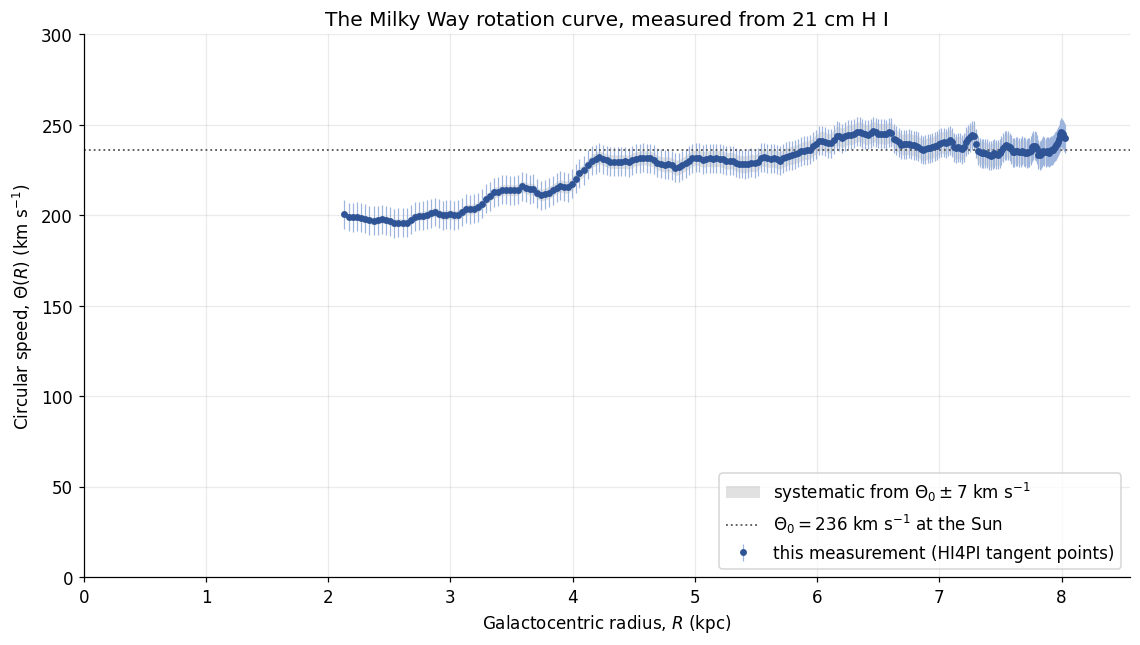

In [ ]:
fig, ax = plt.subplots(figsize=(10.5, 6))







band = THETA0_ERR_KMS * curve["sin_l"]

ax.fill_between(curve["R_kpc"], curve["Theta_kms"] - band, curve["Theta_kms"] + band,
                color=GREY, alpha=0.18, lw=0,
                label=rf"systematic from $\Theta_0 \pm {THETA0_ERR_KMS:.0f}$ km s$^{ -1} $")


ax.errorbar(curve["R_kpc"], curve["Theta_kms"], yerr=curve["Theta_err_kms"],
            fmt="o", ms=3.5, lw=0.8, color=BLUE, ecolor="#9DB4DC", capsize=0,
            label="this measurement (HI4PI tangent points)")
ax.axhline(THETA0_KMS, color=GREY, ls=":", lw=1.2,
           label=rf"$\Theta_0 = {THETA0_KMS:.0f}$ km s$^{ -1} $ at the Sun")





ax.set_xlabel("Galactocentric radius, $R$ (kpc)")
ax.set_ylabel(r"Circular speed, $\Theta(R)$ (km s$^{-1}$)")
ax.set_title("The Milky Way rotation curve, measured from 21 cm H I")
ax.set_xlim(0, R0_KPC * 1.05)


ax.set_ylim(0, max(300, curve.Theta_kms.max() * 1.15))
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figures" / "05_rotation_curve.png", dpi=150)
plt.show()

### 11.3 — Before and after the correction



The point it makes: the correction changed the **zero point** and left the **shape** untouched,
which is exactly what an additive systematic should do. If the shape had changed, the correction
would be doing something we did not intend and we should not trust it.

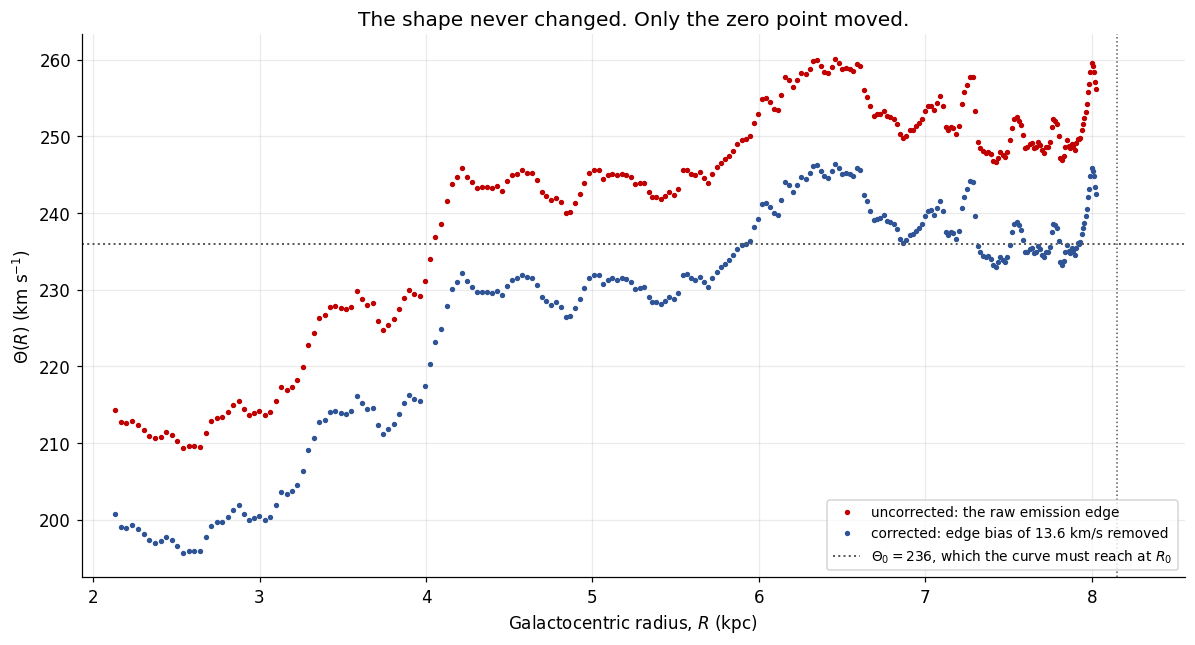

At the outer edge: uncorrected reads 256 km/s, corrected reads 243 km/s.
The value it has to reach is 236 km/s.


In [ ]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(curve["R_kpc"], curve["Theta_raw_kms"], ".", ms=5, color=RED,
        label="uncorrected: the raw emission edge")
ax.plot(curve["R_kpc"], curve["Theta_kms"], ".", ms=5, color=BLUE,
        label=f"corrected: edge bias of {EDGE_BIAS:.1f} km/s removed")
ax.axhline(THETA0_KMS, color=GREY, ls=":", lw=1.3,
           label=rf"$\Theta_0 = {THETA0_KMS:.0f}$, which the curve must reach at $R_0$")
ax.axvline(R0_KPC, color=GREY, ls=":", lw=1.0)
ax.set_xlabel("Galactocentric radius, $R$ (kpc)")
ax.set_ylabel(r"$\Theta(R)$ (km s$^{-1}$)")
ax.set_title("The shape never changed. Only the zero point moved.")
ax.set_xlim(curve.R_kpc.min() - 0.2, R0_KPC * 1.05)
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figures" / "11_before_and_after_correction.png", dpi=150)
plt.show()




print(f"At the outer edge: uncorrected reads {curve['Theta_raw_kms'].iloc[-1]:.0f} km/s, "
      f"corrected reads {curve['Theta_kms'].iloc[-1]:.0f} km/s.")
print(f"The value it has to reach is {THETA0_KMS:.0f} km/s.")

---
# STEP 12 — From velocity to mass

Rearranging the master equation,

$$M(<R) = \frac{\Theta^2(R)\,R}{G}$$

and with $G$ in the astronomer-friendly units from Step 2, feeding in $\Theta$ in km/s and $R$ in
kpc returns the enclosed mass directly in solar masses.

The formula assumes a *spherical*
mass distribution, and the Milky Way's disk is emphatically not spherical — a flattened disk
produces a somewhat higher rotation speed than the same mass arranged in a sphere. What we are
computing is a **dynamical mass estimate**: correct in scale and, more importantly, correct in how
it *scales with radius*. It is not a precision measurement of the Galaxy's mass, and it is
certainly not a decomposition into bulge, disk, gas and halo.

In [ ]:



curve["M_enclosed_Msun"] = curve["Theta_kms"] ** 2 * curve["R_kpc"] / G_ASTRO

print("Enclosed mass at selected radii, read off the measured curve:\n")
rows = []
for R_target in [3, 4, 5, 6, 7, 8]:

    if not (curve.R_kpc.min() <= R_target <= curve.R_kpc.max()):
        continue



    Th = float(np.interp(R_target, curve.R_kpc, curve.Theta_kms))
    rows.append({"R (kpc)": R_target, "Theta (km/s)": round(Th, 1),
                 : f"{Th**2 * R_target / G_ASTRO:.2e}"})
print(pd.DataFrame(rows).to_string(index=False))

Enclosed mass at selected radii, read off the measured curve:

 R (kpc)  Theta (km/s) M(<R) (Msun)
       3         200.5     2.80e+10
       4         218.1     4.43e+10
       5         231.8     6.25e+10
       6         239.9     8.03e+10
       7         239.7     9.35e+10
       8         245.8     1.12e+11


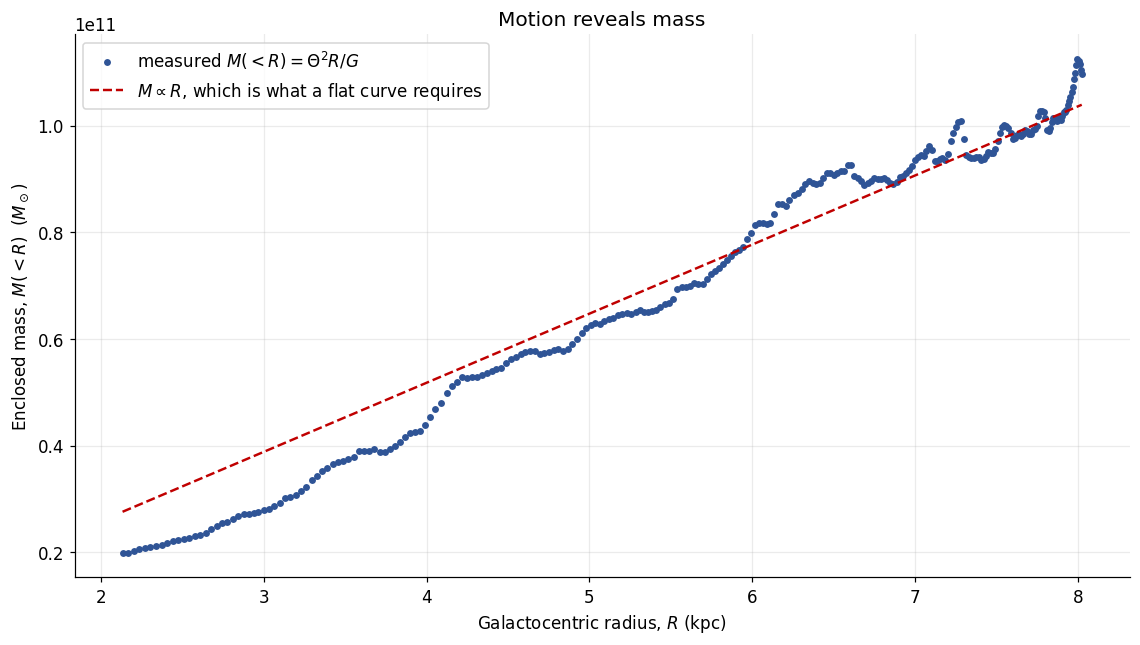

Between R = 2.1 and 8.0 kpc:
  radius grew by a factor 3.8
  enclosed mass grew by a factor 5.5

If all the mass were concentrated at the centre, it would not have grown at all.
The Galaxy keeps handing you more mass the further out you look,
and the starlight is not keeping pace.


In [ ]:
fig, ax = plt.subplots(figsize=(10.5, 6))
ax.plot(curve["R_kpc"], curve["M_enclosed_Msun"], "o", ms=3.5, color=BLUE,
        label=r"measured $M(<R) = \Theta^2 R / G$")


R_ref = np.linspace(curve.R_kpc.min(), curve.R_kpc.max(), 50)
ax.plot(R_ref, THETA0_KMS**2 * R_ref / G_ASTRO, "--", color=RED, lw=1.6,
        label=r"$M \propto R$, which is what a flat curve requires")
ax.set_xlabel("Galactocentric radius, $R$ (kpc)")
ax.set_ylabel(r"Enclosed mass, $M(<R)$  ($M_\odot$)")
ax.set_title("Motion reveals mass")
ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figures" / "06_enclosed_mass.png", dpi=150)
plt.show()



R_lo, R_hi = curve.R_kpc.min(), curve.R_kpc.max()
M_lo = float(np.interp(R_lo, curve.R_kpc, curve.M_enclosed_Msun))
M_hi = float(np.interp(R_hi, curve.R_kpc, curve.M_enclosed_Msun))
print(f"Between R = {R_lo:.1f} and {R_hi:.1f} kpc:")
print(f"  radius grew by a factor {R_hi/R_lo:.1f}")
print(f"  enclosed mass grew by a factor {M_hi/M_lo:.1f}")
print("\nIf all the mass were concentrated at the centre, it would not have grown at all.")
print("The Galaxy keeps handing you more mass the further out you look,")
print("and the starlight is not keeping pace.")

---
# STEP 13 — The comparison that matters

**What we are doing.** Taking the innermost point we measured and asking: if essentially all the
Galaxy's mass were already inside that radius, what should the curve do further out?

It would fall away in Keplerian fashion, $\Theta \propto R^{-1/2}$, exactly like the planets in the
Solar System, where 99.8% of the mass sits in the Sun. (Check it yourself: Neptune orbits 30×
farther out than Earth, and $29.8/\sqrt{30} = 5.4$ km/s, which is Neptune's actual orbital speed.)

**A note on honesty in this figure.** The Keplerian curve is anchored on our innermost measured
point, so it is only as trustworthy as that point. If your inner points are corrupted, this figure
will *exaggerate* the gap. That is precisely why Step 10.2 and `LON_MIN = 15` matter: with a bad
inner point the conclusion is still right, but the picture overstates it.

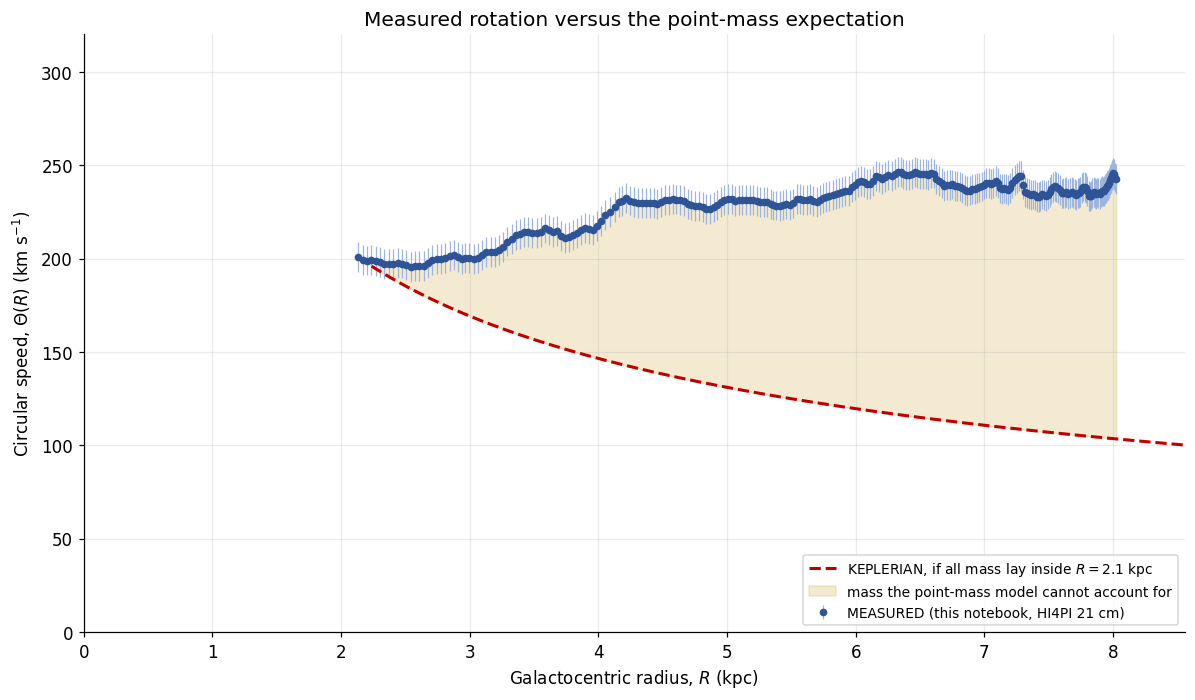

Anchored at R = 2.13 kpc, Theta = 201 km/s

By R = 8.02 kpc:
  Keplerian would have fallen to  103.5 km/s
  we actually measure             242.5 km/s
  ratio of implied enclosed masses: 5.49x

The Galaxy has not run out of mass. That is the argument, in one number.


In [ ]:
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.errorbar(curve["R_kpc"], curve["Theta_kms"], yerr=curve["Theta_err_kms"],
            fmt="o", ms=4, lw=0.8, color=BLUE, ecolor="#9DB4DC", capsize=0,
            label="MEASURED (this notebook, HI4PI 21 cm)")




R_anchor, Th_anchor = float(curve["R_kpc"].iloc[0]), float(curve["Theta_kms"].iloc[0])
R_kep = np.linspace(R_anchor, R0_KPC * 1.05, 200)
ax.plot(R_kep, Th_anchor * np.sqrt(R_anchor / R_kep), "--", color=RED, lw=2,
        label=rf"KEPLERIAN, if all mass lay inside $R = {R_anchor:.1f}$ kpc")


R_fill = np.linspace(R_anchor, float(curve["R_kpc"].max()), 200)
ax.fill_between(R_fill, Th_anchor * np.sqrt(R_anchor / R_fill),
                np.interp(R_fill, curve.R_kpc, curve.Theta_kms),
                color=GOLD, alpha=0.18,
                label="mass the point-mass model cannot account for")





ax.set_xlabel("Galactocentric radius, $R$ (kpc)")
ax.set_ylabel(r"Circular speed, $\Theta(R)$ (km s$^{-1}$)")
ax.set_title("Measured rotation versus the point-mass expectation")
ax.set_xlim(0, R0_KPC * 1.05); ax.set_ylim(0, max(320, curve.Theta_kms.max() * 1.2))
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figures" / "07_measured_vs_keplerian.png", dpi=150)
plt.show()

R_out = float(curve["R_kpc"].iloc[-1])
Th_meas = float(curve["Theta_kms"].iloc[-1])
Th_kep  = Th_anchor * np.sqrt(R_anchor / R_out)
print(f"Anchored at R = {R_anchor:.2f} kpc, Theta = {Th_anchor:.0f} km/s\n")
print(f"By R = {R_out:.2f} kpc:")
print(f"  Keplerian would have fallen to {Th_kep:6.1f} km/s")
print(f"  we actually measure            {Th_meas:6.1f} km/s")

print(f"  ratio of implied enclosed masses: {(Th_meas/Th_kep)**2:.2f}x")
print("\nThe Galaxy has not run out of mass. That is the argument, in one number.")

---
# STEP 14 — Where this method stops, and who carries it further

**Look again at $R = R_0|\sin l|$.** Since $|\sin l| \le 1$, **the tangent-point method can never
probe beyond the Sun's own orbit.** This is not a limitation of HI4PI, of your threshold, or of
your patience. It is geometry. No amount of 21 cm data from inside the solar circle reaches the
outer Galaxy.

**That matters enormously**, because the dark-matter argument really bites *outside* the visible
disk. Inside the solar circle the bulge, the stellar disk and the gas together contribute a large
share of the gravity — so a rising or flat *inner* curve is entirely compatible with a purely
baryonic inner Galaxy.

> **The inner H I curve alone is not a measurement of a dark halo, and presenting it as one is the
> commonest overreach in write-ups of this experiment.**

To get further out you need tracers whose distances are known independently:

- **VLBI maser parallaxes** (Reid et al. 2019) — trigonometric distances to star-forming regions,
  R ≈ 4–16 kpc, with no rotation assumption at all
- **Red giants from Gaia and APOGEE** (Eilers et al. 2019) — R = 5–25 kpc, 23,000 stars
- **Classical Cepheids** (Mróz et al. 2019) — R = 4–20 kpc

The cell below overlays the Eilers et al. linear fit: $v_c(R_\odot) = 229.0 \pm 0.2$ km/s with a
gradient of $-1.7 \pm 0.1$ km/s per kpc. That is their fitted line, not their data points.



> *The gold line is gently declining, not flat. Doesn't that spoil the argument?*

No. A Keplerian fall from R₀ to 25 kpc would lose about 45% of the speed; the observed decline is
about 12%. Slowly declining is still overwhelmingly non-Keplerian.

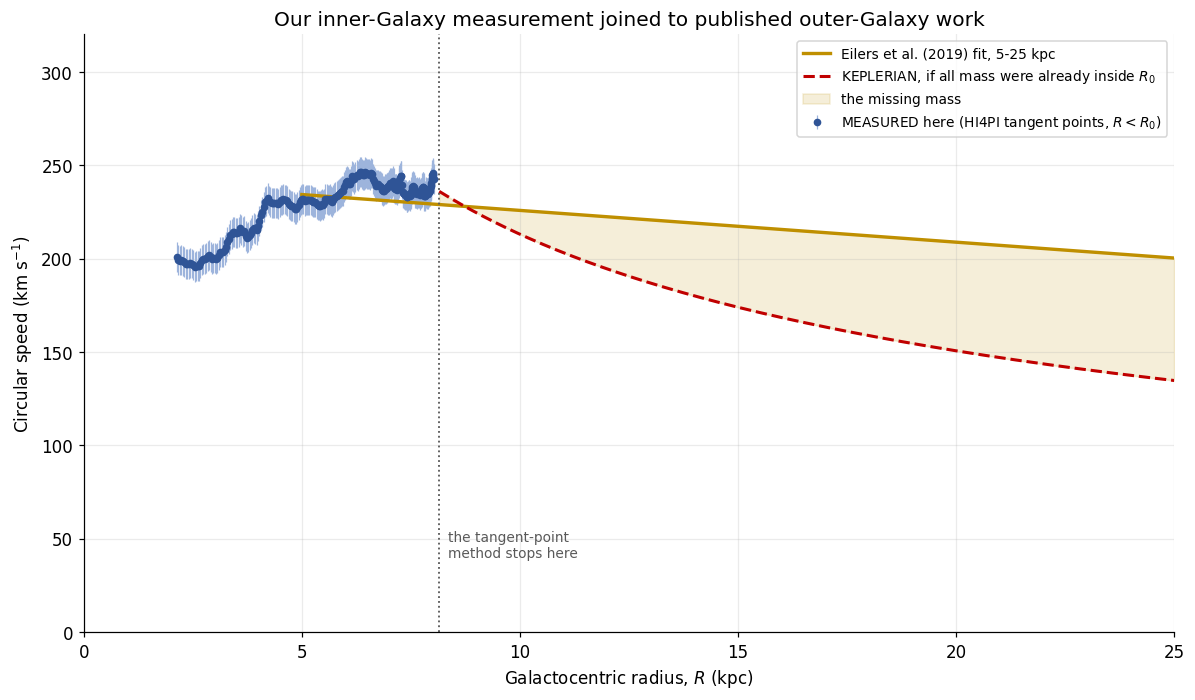

At R = 25 kpc: Keplerian gives 135 km/s, observations give 200 km/s.
Squaring the ratio: 2.2 times more mass inside 25 kpc than
the visible matter can explain.

How our corrected curve compares with published work:

 R (kpc)  uncorrected  corrected  Eilers 2019
     5.0        245.5      231.8        234.3
     6.0        253.5      239.9        232.6
     7.0        253.4      239.7        230.9
     7.8        250.2      236.5        229.5

The correction was measured only at l >= 70 deg, i.e. at R > 7.7 kpc.
If it also agrees at 5 and 6 kpc, that agreement is a genuine test —
not something we put in by hand.


In [ ]:



def eilers_fit(R):  return 229.0 - 1.7 * (R - 8.122)

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.errorbar(curve["R_kpc"], curve["Theta_kms"], yerr=curve["Theta_err_kms"],
            fmt="o", ms=4, lw=0.8, color=BLUE, ecolor="#9DB4DC", capsize=0,
            label="MEASURED here (HI4PI tangent points, $R < R_0$)")



R_outer = np.linspace(5.0, 25.0, 100)
ax.plot(R_outer, eilers_fit(R_outer), "-", color=GOLD, lw=2.2,
        label="Eilers et al. (2019) fit, 5-25 kpc")

R_kep = np.linspace(R0_KPC, 25.0, 200)
ax.plot(R_kep, THETA0_KMS * np.sqrt(R0_KPC / R_kep), "--", color=RED, lw=2,
        label=r"KEPLERIAN, if all mass were already inside $R_0$")
ax.fill_between(R_kep, THETA0_KMS * np.sqrt(R0_KPC / R_kep), eilers_fit(R_kep),
                color=GOLD, alpha=0.15, label="the missing mass")

ax.axvline(R0_KPC, color=GREY, ls=":", lw=1.2)
ax.text(R0_KPC + 0.2, 40, "the tangent-point\nmethod stops here", fontsize=9, color=GREY)
ax.set_xlabel("Galactocentric radius, $R$ (kpc)")
ax.set_ylabel(r"Circular speed (km s$^{-1}$)")
ax.set_title("Our inner-Galaxy measurement joined to published outer-Galaxy work")
ax.set_xlim(0, 25); ax.set_ylim(0, 320)
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figures" / "08_full_rotation_curve.png", dpi=150)
plt.show()




kep25, obs25 = THETA0_KMS * np.sqrt(R0_KPC / 25), eilers_fit(25.0)
print(f"At R = 25 kpc: Keplerian gives {kep25:.0f} km/s, observations give {obs25:.0f} km/s.")
print(f"Squaring the ratio: {(obs25/kep25)**2:.1f} times more mass inside 25 kpc than")
print("the visible matter can explain.\n")





print("How our corrected curve compares with published work:\n")
rows = []
for R_t in [5.0, 6.0, 7.0, 7.8]:
    if not (curve.R_kpc.min() <= R_t <= curve.R_kpc.max()):
        continue
    rows.append({"R (kpc)": R_t,
                 : round(float(np.interp(R_t, curve.R_kpc, curve.Theta_raw_kms)), 1),
                 :   round(float(np.interp(R_t, curve.R_kpc, curve.Theta_kms)), 1),
                 : round(eilers_fit(R_t), 1)})
print(pd.DataFrame(rows).to_string(index=False))
print(f"\nThe correction was measured only at l >= {CALIB_LON_MIN:.0f} deg, i.e. at R > "
      f"{R0_KPC*np.sin(np.deg2rad(CALIB_LON_MIN)):.1f} kpc.")
print("If it also agrees at 5 and 6 kpc, that agreement is a genuine test —")
print("not something we put in by hand.")

---
# STEP 15 — Save everything

**What we are doing.** Writing out the l–v diagram, the per-sightline measurements, the binned
curve, an Excel workbook, a blank table for students to fill in by hand, and a machine-readable
record of every setting used.

**The run record is the part to take seriously.** It contains every dial, every constant, the
checksum of every input file, and the library versions. Anyone handed that JSON can reproduce our
figures exactly. That habit is worth more than any single result.

In [ ]:
proc = OUTPUT_DIR / "processed"




np.savez_compressed(proc / "lv_diagram.npz", velocity_kms=velocity,
                    longitude_deg=longitude, brightness_temperature_k=lv)



terminal.to_csv(proc / "terminal_velocities_per_sightline.csv", index=False)
curve.to_csv(proc / "rotation_curve.csv", index=False)
comparison.to_csv(proc / "criterion_sensitivity.csv", index=False)



student_lon = np.arange(LON_MIN, LON_MAX + 1, 5.0)
student = pd.DataFrame({
    : student_lon,
    : "",
    : np.round(R0_KPC * np.sin(np.deg2rad(student_lon)), 2),
    : np.round(THETA0_KMS * np.sin(np.deg2rad(student_lon)), 1),
    : "",
})
student.to_csv(proc / "student_blank_table.csv", index=False)



with pd.ExcelWriter(proc / "milky_way_rotation.xlsx", engine="openpyxl") as writer:
    curve.to_excel(writer, sheet_name="rotation_curve", index=False)
    terminal.to_excel(writer, sheet_name="terminal_velocities", index=False)
    comparison.to_excel(writer, sheet_name="criterion_sensitivity", index=False)
    student.to_excel(writer, sheet_name="student_blank_table", index=False)

print("Tables written.")

Tables written.


In [ ]:




record = {
    : {"timestamp_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
            : np.__version__, "pandas": pd.__version__},
    : {
        : QUADRANT, "lon_min": LON_MIN, "lon_max": LON_MAX,
        : LAT_ABS_MAX,
        : VELOCITY_MIN, "velocity_max": VELOCITY_MAX,
        : SEARCH_MIN, "search_max": SEARCH_MAX,
        : THRESHOLD_METHOD, "absolute_k": ABSOLUTE_K,
        : PEAK_FRACTION, "min_channels": MIN_CHANNELS,
        : LON_BIN_DEG,
        : CALIBRATE_EDGE_BIAS, "calib_lon_min": CALIB_LON_MIN,
    },
    : {"R0_kpc": R0_KPC, "R0_err_kpc": R0_ERR_KPC,
                          : THETA0_KMS, "Theta0_err_kms": THETA0_ERR_KMS,
                          : G_ASTRO, "nu0_MHz": NU_0_MHZ},
    : {"survey": "HI4PI (Ben Bekhti et al. 2016, A&A 594, A116)",
             : downloads.to_dict("records")},
    : {


        : int(len(terminal)),
        : int((terminal["flag"] == "OK").sum()),
        : int(len(curve)),
        : round(float(EDGE_BIAS), 2),
        : [float(curve.R_kpc.min()), float(curve.R_kpc.max())],
        : float(curve.Theta_kms.median()),
        : float(curve.Theta_kms.iloc[-1]),
        : terminal["flag"].value_counts().to_dict(),
    },
}

(OUTPUT_DIR / "run_record.json").write_text(json.dumps(record, indent=2))

bundle = Path("milky_way_rotation_bundle.zip")
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as zf:


    for path in OUTPUT_DIR.rglob("*"):
        if path.is_file() and "raw" not in path.parts:
            zf.write(path, path.relative_to(OUTPUT_DIR))

print(f"Bundle written: {bundle} ({bundle.stat().st_size/1e6:.1f} MB)\n")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file() and "raw" not in path.parts:
        print("  ", path.relative_to(OUTPUT_DIR))

Bundle written: milky_way_rotation_bundle.zip (2.5 MB)

   figures/01_lv_diagram.png
   figures/02_sample_spectra.png
   figures/03_terminal_velocity_overlay.png
   figures/04_threshold_on_spectra.png
   figures/05_rotation_curve.png
   figures/06_enclosed_mass.png
   figures/07_measured_vs_keplerian.png
   figures/08_full_rotation_curve.png
   figures/10_edge_bias_calibration.png
   figures/11_before_and_after_correction.png
   processed/criterion_sensitivity.csv
   processed/lv_diagram.npz
   processed/milky_way_rotation.xlsx
   processed/rotation_curve.csv
   processed/student_blank_table.csv
   processed/terminal_velocities_per_sightline.csv
   run_record.json


In [ ]:



try:
    from google.colab import files
    files.download(str(bundle))
except Exception:
    print("Not running in Colab. The bundle is on disk at:", bundle.resolve())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>